# NGC 1566 source-geometry systematic: H-alpha log spiral

This notebook constructs a Li et al. (2021)-style two-dimensional metallicity
fluctuation map directly from the public PHANGS--MUSE emission-line maps for
NGC 1566.  It does **not** use the Williams et al. Gaussian-process metallicity
reconstruction and does not paint one integrated abundance over each nebular
footprint.

The calculation has three observation and inference layers:

1. The official `copt` PHANGS--MUSE MAPS product supplies per-spaxel H-beta,
   [O III], H-alpha, [N II], and [S II] fluxes and formal errors.  The line maps
   are brought from the released 0.80 arcsec Gaussian PSF to a 120 pc Gaussian
   PSF, sampled on a 60 pc face-on grid, attenuation-corrected, and converted
   to $12+\log({\rm O/H})$ with the Pilyugin & Grebel (2016) $S$ calibration.
   A matched `copt` SDSS-$r$ image provides the continuum-density proxy used
   for the Li21 $\mathrm{EW}({\rm H}\alpha)>6$ Angstrom cut.  The proxy is
   calibrated in each galaxy against the released region-integrated H-alpha
   equivalent widths.
2. The abundance field uses every spaxel in the analysis window that passes
   the Li21 selection: all required lines have $S/N\geq2$, the line ratios lie
   below the Kewley star-forming boundary, and
   $\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  Membership in a segmented HII
   region is **not** required.  An independent mean is then subtracted in every
   0.2 kpc annulus.  Missing cells remain `NaN`; neither pixels nor pairs are
   randomly subsampled.
3. The systematic KTZ fit retains seven free parameters and includes
   the optional isotropic appendix $C_{\rm NP}$ term.  The fixed observational transfer
   includes the Li21 Gaussian-beam broadening and a line-flux Monte Carlo
   estimate of the correlated measurement-noise contribution.  Its source
geometry is fitted to H-alpha-weighted, arm-labelled HII regions before
the metallicity map is inspected.  The same annular-mean projector used
for the data is applied to every model curve on the actual finite mask.
The displayed
   $r=0$ point is fixed to unity and is excluded from the likelihood.

Data sources:

- [PHANGS--MUSE DR1 release](https://www.eso.org/rm/api/v1/public/releaseDescriptions/184)
- [PHANGS--MUSE survey](https://doi.org/10.1051/0004-6361/202141727)
- [PHANGS--MUSE Nebula Catalogue DR1.1](https://www.eso.org/qi/catalog/show/436)
- [Pilyugin & Grebel (2016)](https://doi.org/10.1093/mnras/stw238)


In [1]:
from __future__ import annotations

import hashlib
from io import BytesIO
import json
import shutil
import sys
import tarfile
from pathlib import Path
from urllib.request import urlopen

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
from IPython.display import Image, Markdown, display
from scipy.integrate import simpson
from scipy.ndimage import gaussian_filter, map_coordinates
from scipy.signal import fftconvolve
from scipy.spatial import cKDTree
from scipy.special import exp1
from scipy.stats import chi2, linregress

ROOT = Path.cwd()
GALAXY_NAME = "NGC1566"
DATA_ROOT = ROOT / "data" / "phangs"
OUTPUT_ROOT = ROOT / "outputs" / "implications"
DATA_DIR = DATA_ROOT / "NGC1566"
OUTPUT_DIR = OUTPUT_ROOT / "NGC1566_logspiral_systematic"
CATALOG_PATH = DATA_DIR / "NGC1566_catalog.fits"
NEBULA_MASK_PATH = DATA_DIR / "NGC1566_nebulae_mask.fits"
MUSE_MAPS_PATH = DATA_DIR / "NGC1566_MAPS_copt_0.80asec.fits"
R_BAND_PATH = DATA_DIR / "NGC1566_PHANGS_IMAGE_SDSS_r_copt_0.80asec.fits"
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.grid": False,
})


def display_figure(figure):
    """Render without calling show() on a non-interactive Agg canvas."""
    buffer = BytesIO()
    figure.savefig(buffer, format="png", dpi=plt.rcParams["figure.dpi"],
                   bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


# NGC 1566 geometry used by the PHANGS catalogue.
DISTANCE_MPC = 17.7
R25_ARCMIN = 3.6
INCLINATION_DEG = 29.5
POSITION_ANGLE_DEG = 214.7
R25_KPC = DISTANCE_MPC * 1.0e3 * np.tan(np.deg2rad(R25_ARCMIN / 60.0))

# Spatial and quality choices for the direct MUSE map.
COPT_PSF_FWHM_ARCSEC = 0.80
TARGET_FWHM_KPC = 0.120
PIXEL_SIZE_KPC = 0.060
ANNULUS_WIDTH_KPC = 0.20
LINE_SN_MIN = 2.0
LINE_COVERAGE_MIN = 0.80
HALPHA_EW_MIN_ANGSTROM = 6.0
METALLICITY_ERROR_MAX_DEX = None
MUSE_ERROR_INFLATION = 1.12
N_FLUX_MC = 200
MIN_PIXELS_PER_ANNULUS = 20
R_MIN_R25 = 0.10
R_MAX_R25 = 0.40
R_MIN_KPC = R_MIN_R25 * R25_KPC
R_MAX_KPC = R_MAX_R25 * R25_KPC

print(f"R25 = {R25_KPC:.3f} kpc; analysis annulus = "
      f"[{R_MIN_KPC:.3f}, {R_MAX_KPC:.3f}] kpc")
print(f"Target PSF/pixel = {TARGET_FWHM_KPC:.3f}/{PIXEL_SIZE_KPC:.3f} kpc")


R25 = 18.535 kpc; analysis annulus = [1.854, 7.414] kpc
Target PSF/pixel = 0.120/0.060 kpc


## 1. Download the PHANGS--MUSE line maps, continuum image, and masks

The primary abundance input is the official 0.80 arcsec `copt` MAPS file, not
a reconstructed metallicity field.  The matched synthetic SDSS-$r$ image has
flux-density units and supplies the local continuum proxy for the H-alpha
equivalent-width cut.  The nebular catalogue and mask calibrate that proxy and
determine the large-scale arm geometry; they do not select abundance pixels.
The MAPS and SDSS-$r$ downloads are approximately 431 MiB and 9 MiB.

Set `FORCE_DOWNLOAD=True` only when the archived products should be refreshed.


In [2]:
CATALOG_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.227"
)
NEBULA_MASK_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2025-05-14T09:12:30.228"
)
MUSE_MAPS_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.422"
)
R_BAND_URL = (
    "https://dataportal.eso.org/dataPortal/file/"
    "ADP.2021-07-16T10:20:56.420"
)
MUSE_MAPS_PRODUCT_ID = "ADP.2021-07-16T10:20:56.422"
R_BAND_PRODUCT_ID = "ADP.2021-07-16T10:20:56.420"


def download_product(url: str, path: Path, force: bool = False) -> Path:
    """Download one public product atomically."""
    if path.exists() and not force:
        return path
    temporary = path.with_suffix(path.suffix + ".part")
    with urlopen(url, timeout=300) as response:
        with temporary.open("wb") as stream:
            shutil.copyfileobj(response, stream)
    temporary.replace(path)
    return path


def sha256_file(path: Path, chunk_size: int = 8 * 1024**2) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        while chunk := stream.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


FORCE_DOWNLOAD = False
for product_url, product_path in (
    (CATALOG_URL, CATALOG_PATH),
    (NEBULA_MASK_URL, NEBULA_MASK_PATH),
    (MUSE_MAPS_URL, MUSE_MAPS_PATH),
    (R_BAND_URL, R_BAND_PATH),
):
    download_product(product_url, product_path, force=FORCE_DOWNLOAD)

catalog_hash = sha256_file(CATALOG_PATH)
nebula_mask_hash = sha256_file(NEBULA_MASK_PATH)
muse_maps_hash = sha256_file(MUSE_MAPS_PATH)
r_band_hash = sha256_file(R_BAND_PATH)
for product_name, product_path, product_hash in (
    ("PHANGS nebular catalogue", CATALOG_PATH, catalog_hash),
    ("PHANGS nebular mask", NEBULA_MASK_PATH, nebula_mask_hash),
    ("PHANGS--MUSE copt MAPS", MUSE_MAPS_PATH, muse_maps_hash),
    ("PHANGS--MUSE copt SDSS-r continuum", R_BAND_PATH, r_band_hash),
):
    print(f"{product_name}: {product_path}")
    print(f"Size: {product_path.stat().st_size / 1024**2:.2f} MiB")
    print(f"SHA256: {product_hash}")


# Querejeta et al. (2021) PHANGS pixel-level environment masks.
PHANGS_ENVIRONMENT_MASK_BUNDLE_URL = (
    "https://www.canfar.net/storage/vault/file/AstroDataCitationDOI/"
    "CISTI.CANFAR/21.0024/data/PHANGS_env_masks.bundle.tar.gz"
)
ENVIRONMENT_ARCHIVE_DIR = DATA_ROOT / "environment_masks"
ENVIRONMENT_ARCHIVE_DIR.mkdir(parents=True, exist_ok=True)
ENVIRONMENT_BUNDLE_PATH = (
    ENVIRONMENT_ARCHIVE_DIR / "PHANGS_env_masks.bundle.tar.gz"
)
mask_galaxy_name = "NGC0628" if GALAXY_NAME == "NGC628" else GALAXY_NAME
mask_member = (
    "PHANGS_env_masks/env_masks_simple/"
    f"{mask_galaxy_name}_env_mask_simple.fits"
)
ENVIRONMENT_MASK_PATH = ENVIRONMENT_ARCHIVE_DIR / mask_member
if not ENVIRONMENT_MASK_PATH.exists() or FORCE_DOWNLOAD:
    # the bundle is fetched only when the extracted mask is missing (offline re-runs)
    download_product(
        PHANGS_ENVIRONMENT_MASK_BUNDLE_URL, ENVIRONMENT_BUNDLE_PATH,
        force=FORCE_DOWNLOAD,
    )
    with tarfile.open(ENVIRONMENT_BUNDLE_PATH, "r:gz") as archive:
        archive.extract(mask_member, path=ENVIRONMENT_ARCHIVE_DIR, filter="data")
environment_mask_hash = sha256_file(ENVIRONMENT_MASK_PATH)
print(f"PHANGS environment mask: {ENVIRONMENT_MASK_PATH}")
print(f"SHA256: {environment_mask_hash}")


PHANGS nebular catalogue: /home/claude/ktzobs/data/phangs/NGC1566/NGC1566_catalog.fits
Size: 1.41 MiB
SHA256: c996842ffa04ee68745aa4266b56b771ac39ebe63ece6a3e42a29119d34919fe
PHANGS nebular mask: /home/claude/ktzobs/data/phangs/NGC1566/NGC1566_nebulae_mask.fits
Size: 4.07 MiB
SHA256: e799de7012aaef6fb591b984a11a6da492219c99c5eec0934b0e0bfa3dbe208f
PHANGS--MUSE copt MAPS: /home/claude/ktzobs/data/phangs/NGC1566/NGC1566_MAPS_copt_0.80asec.fits
Size: 431.18 MiB
SHA256: 1059f563ed4f7c8b56eddbed36add518e974b36b6ab294dddcfd3fe64f7fe325
PHANGS--MUSE copt SDSS-r continuum: /home/claude/ktzobs/data/phangs/NGC1566/NGC1566_PHANGS_IMAGE_SDSS_r_copt_0.80asec.fits
Size: 9.18 MiB
SHA256: 3921b5c99989864ad0e594b45003282ac7ed7283ba8119268f0f8b3dbf8a29f6
PHANGS environment mask: /home/claude/ktzobs/data/phangs/environment_masks/PHANGS_env_masks/env_masks_simple/NGC1566_env_mask_simple.fits
SHA256: 72916d25013c88dd37fc54c9be214152387956cd98401db95ac948ee39a12d68


## 2. Establish the face-on geometry and an independent H-alpha spiral template

The catalogue supplies the HII-region classifications and the coordinates used
to fit a robust affine sky-to-face-on transformation. The non-axisymmetric
source geometry is never fitted to the metallicity map. Instead, labels 5 and 6
in the released Querejeta et al. (2021) environment classification select an
H-alpha-weighted HII-region sample. We fit its arm number, logarithmic pitch,
and phase before evaluating the abundance statistic. The first three source
harmonics and the radial event-rate profile are then measured from the direct,
attenuation-corrected H-alpha grid.


In [3]:
catalog = Table.read(CATALOG_PATH)


def numeric_column(name: str) -> np.ndarray:
    return np.asarray(np.ma.asarray(catalog[name]).filled(np.nan), dtype=float)


catalog_r_r25 = numeric_column("DEPROJ_R_R25")
catalog_r_kpc = catalog_r_r25 * R25_KPC
catalog_phi = numeric_column("DEPROJ_PHI")
catalog_target_xy = np.column_stack((
    catalog_r_kpc * np.cos(catalog_phi),
    catalog_r_kpc * np.sin(catalog_phi),
))
catalog_ra = numeric_column("RAJ2000")
catalog_dec = numeric_column("DECJ2000")
sky_reference_ra = float(np.nanmedian(catalog_ra))
sky_reference_dec = float(np.nanmedian(catalog_dec))


def sky_design_matrix(ra_deg: np.ndarray, dec_deg: np.ndarray) -> np.ndarray:
    """Return local east, north [kpc] and an affine intercept column."""
    ra_deg = np.asarray(ra_deg, dtype=float)
    dec_deg = np.asarray(dec_deg, dtype=float)
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    east = ((ra_deg - sky_reference_ra)
            * np.cos(np.deg2rad(sky_reference_dec)) * angular_to_kpc)
    north = (dec_deg - sky_reference_dec) * angular_to_kpc
    return np.column_stack((east, north, np.ones_like(east)))


catalog_sky_design = sky_design_matrix(catalog_ra, catalog_dec)
transform_inlier = (
    np.all(np.isfinite(catalog_sky_design), axis=1)
    & np.all(np.isfinite(catalog_target_xy), axis=1)
)
for _ in range(6):
    face_on_affine = np.linalg.lstsq(
        catalog_sky_design[transform_inlier],
        catalog_target_xy[transform_inlier], rcond=None,
    )[0]
    transform_residual = np.hypot(*(
        catalog_sky_design @ face_on_affine - catalog_target_xy
    ).T)
    median_residual = np.median(transform_residual[transform_inlier])
    residual_mad = np.median(np.abs(
        transform_residual[transform_inlier] - median_residual
    ))
    clipping_radius = max(0.10, median_residual + 10.0 * 1.4826 * residual_mad)
    transform_inlier = np.isfinite(transform_residual) & (
        transform_residual < clipping_radius
    )


def project_sky_to_face_on(
    ra_deg: np.ndarray, dec_deg: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = sky_design_matrix(ra_deg, dec_deg) @ face_on_affine
    return xy[:, 0], xy[:, 1]


def project_face_on_to_sky(
    x_kpc: np.ndarray, y_kpc: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    xy = np.column_stack((np.ravel(x_kpc), np.ravel(y_kpc)))
    east_north = (xy - face_on_affine[2]) @ np.linalg.inv(face_on_affine[:2])
    angular_to_kpc = np.pi / 180.0 * DISTANCE_MPC * 1.0e3
    ra = (sky_reference_ra + east_north[:, 0]
          / (angular_to_kpc * np.cos(np.deg2rad(sky_reference_dec))))
    dec = sky_reference_dec + east_north[:, 1] / angular_to_kpc
    return ra, dec


face_on_x_all, face_on_y_all = project_sky_to_face_on(catalog_ra, catalog_dec)
face_on_r_kpc_all = np.hypot(face_on_x_all, face_on_y_all)
face_on_phi_all = np.mod(np.arctan2(face_on_y_all, face_on_x_all), 2.0 * np.pi)
r_r25_all = catalog_r_r25

catalog_hii_quality = (
    (numeric_column("FLAG_EDGE") == 0)
    & (numeric_column("FLAG_STAR") == 0)
    & (numeric_column("BPT_NII") == 0)
    & np.isfinite(numeric_column("HA6562_LUM_CORR"))
    & (numeric_column("HA6562_LUM_CORR") > 0)
)
source_mask = (
    catalog_hii_quality
    & (r_r25_all >= R_MIN_R25)
    & (r_r25_all <= R_MAX_R25)
)
source_r_kpc_catalog = face_on_r_kpc_all[source_mask]
source_phi_catalog = face_on_phi_all[source_mask]
source_environment_catalog = numeric_column("ENVIRONMENT")[source_mask].astype(int)
source_halpha_catalog = numeric_column("HA6562_LUM_CORR")[source_mask]
source_catalog_weights = source_halpha_catalog / np.sum(source_halpha_catalog)
r_ref_kpc = float(np.exp(np.sum(
    source_catalog_weights * np.log(source_r_kpc_catalog)
)))
hii_region_ids = numeric_column("REGION_ID")[catalog_hii_quality].astype(int)

environment_labels, environment_counts = np.unique(
    source_environment_catalog, return_counts=True
)
display(Table({
    "environment_label": environment_labels,
    "qualified_HII_regions": environment_counts,
}))


environment_label,qualified_HII_regions
int64,int64
2,16
3,58
4,87
5,95
6,455
7,468


## 3. Construct the Li21-style spaxel metallicity fluctuation map

All available line fluxes and the SDSS-$r$ continuum-density image are first
brought to a common 120 pc Gaussian PSF and then sampled on a 60 pc face-on
grid.  Ratios and abundances are calculated only after this linear processing.
Internal attenuation is inferred from the Balmer decrement using an O'Donnell
$R_V=3.1$ curve.  The Pilyugin & Grebel (2016) $S$ calibration uses $R_3$,
$N_2$, and $S_2$; its upper/lower branch is selected independently in every
cell.

Following Li21, pixels are retained when every line needed by the diagnostic
has $S/N\geq2$, the [N II] BPT ratios lie below the Kewley boundary, and
$\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  The public MAPS product does not
contain a continuum extension, so the matched synthetic SDSS-$r$ flux density
is used for the continuum.  Its H-alpha/continuum ratio is calibrated against
the catalogue's fitted region-integrated H-alpha equivalent widths; the
calibration scatter is reported below.  The nebular segmentation never enters
the abundance-pixel mask.  Missing cells are `NaN`, never physical zeros.


In [4]:
LINE_EXTENSIONS = {
    "hb": "HB4861",
    "oiii": "OIII5006",
    "ha": "HA6562",
    "nii": "NII6583",
    "sii6716": "SII6716",
    "sii6730": "SII6730",
}
LINE_WAVELENGTH_ANGSTROM = {
    "hb": 4861.35,
    "oiii": 5006.84,
    "ha": 6562.79,
    "nii": 6583.45,
    "sii6716": 6716.44,
    "sii6730": 6730.82,
}


def odonnell_k(wavelength_angstrom: float, rv: float = 3.1) -> float:
    """O'Donnell (1994) optical A(lambda)/E(B-V)."""
    x = 1.0 / (wavelength_angstrom * 1.0e-4)
    y = x - 1.82
    a = (1.0 + 0.104*y - 0.609*y**2 + 0.701*y**3 + 1.137*y**4
         - 1.718*y**5 - 0.827*y**6 + 1.647*y**7 - 0.505*y**8)
    b = (1.952*y + 2.908*y**2 - 3.989*y**3 - 7.985*y**4
         + 11.102*y**5 + 5.491*y**6 - 10.805*y**7 + 3.347*y**8)
    return float(rv * a + b)


extinction_k = {
    name: odonnell_k(wavelength)
    for name, wavelength in LINE_WAVELENGTH_ANGSTROM.items()
}

grid_half_pixels = int(np.ceil(R_MAX_KPC / PIXEL_SIZE_KPC))
pixel_centres = np.arange(-grid_half_pixels, grid_half_pixels + 1) * PIXEL_SIZE_KPC
pixel_X, pixel_Y = np.meshgrid(pixel_centres, pixel_centres)
pixel_R = np.hypot(pixel_X, pixel_Y)
pixel_PHI = np.mod(np.arctan2(pixel_Y, pixel_X), 2.0 * np.pi)
target_ra, target_dec = project_face_on_to_sky(pixel_X, pixel_Y)


def gaussian_kernel_square_sum(sigma_pixel: float, truncate: float = 4.0) -> float:
    if sigma_pixel <= 0:
        return 1.0
    radius = int(truncate * sigma_pixel + 0.5)
    coordinate = np.arange(-radius, radius + 1, dtype=float)
    kernel_1d = np.exp(-0.5 * (coordinate / sigma_pixel)**2)
    kernel_1d /= np.sum(kernel_1d)
    return float(np.sum(kernel_1d**2)**2)


def smooth_and_sample_line(
    flux_native: np.ndarray, error_native: np.ndarray,
    sample_coordinates: np.ndarray, sigma_pixel: float,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """PSF-match surface-brightness and sample it on the face-on grid."""
    good = np.isfinite(flux_native) & np.isfinite(error_native) & (error_native > 0)
    flux_zero = np.where(good, flux_native, 0.0).astype(np.float32)
    variance_zero = np.where(good, error_native**2, 0.0).astype(np.float32)
    if sigma_pixel > 0:
        weight = gaussian_filter(good.astype(np.float32), sigma_pixel,
                                 mode="constant", cval=0.0, truncate=4.0)
        numerator = gaussian_filter(flux_zero, sigma_pixel, mode="constant",
                                    cval=0.0, truncate=4.0)
        # For independent native-pixel errors, convolution by K propagates
        # variance with K^2.  K^2 is a narrower Gaussian times sum(K^2).
        variance_numerator = gaussian_filter(
            variance_zero, sigma_pixel / np.sqrt(2.0), mode="constant",
            cval=0.0, truncate=4.0,
        ) * gaussian_kernel_square_sum(sigma_pixel)
        smoothed_flux = np.divide(
            numerator, weight, out=np.full_like(numerator, np.nan),
            where=weight > 0,
        )
        smoothed_error = np.divide(
            np.sqrt(np.clip(variance_numerator, 0.0, None)), weight,
            out=np.full_like(numerator, np.nan), where=weight > 0,
        )
    else:
        weight = good.astype(np.float32)
        smoothed_flux = np.where(good, flux_native, np.nan)
        smoothed_error = np.where(good, error_native, np.nan)

    sampled_flux = map_coordinates(
        smoothed_flux, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_error = map_coordinates(
        smoothed_error, sample_coordinates, order=1, mode="constant", cval=np.nan,
    ).reshape(pixel_X.shape)
    sampled_coverage = map_coordinates(
        weight, sample_coordinates, order=1, mode="constant", cval=0.0,
    ).reshape(pixel_X.shape)
    return sampled_flux, sampled_error, sampled_coverage


with fits.open(MUSE_MAPS_PATH, memmap=True) as maps_hdul:
    required_extensions = [
        suffix + ending
        for suffix in LINE_EXTENSIONS.values()
        for ending in ("_FLUX", "_FLUX_ERR")
    ]
    missing_extensions = [name for name in required_extensions if name not in maps_hdul]
    if missing_extensions:
        raise KeyError(f"Missing PHANGS MAPS extensions: {missing_extensions}")

    map_wcs = WCS(maps_hdul["HA6562_FLUX"].header).celestial
    native_shape = maps_hdul["HA6562_FLUX"].data.shape
    native_pixel_scale_arcsec = (
        np.sqrt(abs(np.linalg.det(map_wcs.pixel_scale_matrix))) * 3600.0
    )
    target_fwhm_arcsec = (
        TARGET_FWHM_KPC / (DISTANCE_MPC * 1.0e3) * 206265.0
    )
    if target_fwhm_arcsec < COPT_PSF_FWHM_ARCSEC:
        raise ValueError("Target PSF is narrower than the released copt PSF.")
    kernel_fwhm_arcsec = np.sqrt(
        target_fwhm_arcsec**2 - COPT_PSF_FWHM_ARCSEC**2
    )
    kernel_sigma_pixel = (
        kernel_fwhm_arcsec / 2.354820045 / native_pixel_scale_arcsec
    )
    target_pixel_x, target_pixel_y = map_wcs.world_to_pixel_values(
        target_ra, target_dec
    )
    target_sample_coordinates = np.vstack((target_pixel_y, target_pixel_x))

    line_flux = {}
    line_error = {}
    line_coverage = {}
    for short_name, extension_root in LINE_EXTENSIONS.items():
        flux_grid, error_grid, coverage_grid = smooth_and_sample_line(
            np.asarray(maps_hdul[extension_root + "_FLUX"].data, dtype=np.float32),
            np.asarray(maps_hdul[extension_root + "_FLUX_ERR"].data,
                       dtype=np.float32),
            target_sample_coordinates,
            kernel_sigma_pixel,
        )
        line_flux[short_name] = flux_grid
        line_error[short_name] = MUSE_ERROR_INFLATION * error_grid
        line_coverage[short_name] = coverage_grid


with fits.open(R_BAND_PATH, memmap=True) as r_band_hdul:
    r_band_wcs = WCS(r_band_hdul["DATA"].header).celestial
    r_band_x, r_band_y = r_band_wcs.world_to_pixel_values(target_ra, target_dec)
    r_band_coordinates = np.vstack((r_band_y, r_band_x))
    r_band_native = np.asarray(r_band_hdul["DATA"].data, dtype=np.float32)
    r_band_variance_native = np.asarray(
        r_band_hdul["STAT"].data, dtype=np.float32
    )
    r_band_dq_native = np.asarray(r_band_hdul["DQ"].data)
    r_band_good_native = (
        (r_band_dq_native == 0) & np.isfinite(r_band_native)
        & np.isfinite(r_band_variance_native) & (r_band_variance_native > 0)
    )
    r_band_flux, r_band_error, r_band_coverage = smooth_and_sample_line(
        np.where(r_band_good_native, r_band_native, np.nan),
        np.where(r_band_good_native, np.sqrt(r_band_variance_native), np.nan),
        r_band_coordinates, kernel_sigma_pixel,
    )


with fits.open(NEBULA_MASK_PATH, memmap=True) as mask_hdul:
    nebula_wcs = WCS(mask_hdul[0].header).celestial
    mask_x, mask_y = nebula_wcs.world_to_pixel_values(target_ra, target_dec)
    region_id_grid = map_coordinates(
        np.asarray(mask_hdul[0].data, dtype=float),
        np.vstack((mask_y, mask_x)), order=0, mode="constant", cval=-1,
    ).reshape(pixel_X.shape).astype(int)


# The synthetic r-band image is in flux-density units.  Calibrate the direct
# H-alpha/r-band ratio against the catalogue's fitted integrated EWs so that
# the Li21 6-Angstrom cut is tied to the released PHANGS measurements rather
# than to an arbitrary surface-brightness threshold.
with np.errstate(divide="ignore", invalid="ignore"):
    raw_halpha_ew_grid = line_flux["ha"] / r_band_flux
catalog_region_id = numeric_column("REGION_ID")
catalog_halpha_ew = numeric_column("EW_HA6562_FIT")
ew_catalog_valid = (
    catalog_hii_quality & np.isfinite(catalog_region_id)
    & np.isfinite(catalog_halpha_ew) & (catalog_halpha_ew > 0)
)
ew_sum_valid = (
    (region_id_grid >= 0) & np.isfinite(line_flux["ha"])
    & np.isfinite(r_band_flux) & (line_flux["ha"] > 0) & (r_band_flux > 0)
)
ew_ids = region_id_grid[ew_sum_valid].astype(int)
ew_halpha_sum = np.bincount(
    ew_ids, weights=line_flux["ha"][ew_sum_valid]
)
ew_continuum_sum = np.bincount(
    ew_ids, weights=r_band_flux[ew_sum_valid], minlength=len(ew_halpha_sum)
)
ew_region_proxy = np.divide(
    ew_halpha_sum, ew_continuum_sum,
    out=np.full_like(ew_halpha_sum, np.nan), where=ew_continuum_sum > 0,
)
ew_catalog_ids = catalog_region_id[ew_catalog_valid].astype(int)
ew_catalog_values = catalog_halpha_ew[ew_catalog_valid]
ew_match = (
    (ew_catalog_ids >= 0) & (ew_catalog_ids < len(ew_region_proxy))
)
ew_scale_samples = np.divide(
    ew_catalog_values[ew_match], ew_region_proxy[ew_catalog_ids[ew_match]],
    out=np.full(np.count_nonzero(ew_match), np.nan),
    where=ew_region_proxy[ew_catalog_ids[ew_match]] > 0,
)
ew_scale_samples = ew_scale_samples[
    np.isfinite(ew_scale_samples) & (ew_scale_samples > 0)
]
if len(ew_scale_samples) < 30:
    raise RuntimeError("Too few PHANGS regions to calibrate the H-alpha EW map.")
ew_scale_log = np.log(ew_scale_samples)
ew_scale_log_median = np.median(ew_scale_log)
ew_scale_log_mad = np.median(np.abs(ew_scale_log - ew_scale_log_median))
if ew_scale_log_mad > 0:
    ew_scale_samples = ew_scale_samples[
        np.abs(np.log(ew_scale_samples) - ew_scale_log_median)
        < 5.0 * 1.4826 * ew_scale_log_mad
    ]
halpha_ew_scale = float(np.median(ew_scale_samples))
halpha_ew_scale_p16, halpha_ew_scale_p84 = np.percentile(
    ew_scale_samples, [16.0, 84.0]
)
halpha_ew_grid = halpha_ew_scale * raw_halpha_ew_grid


def scal_metallicity(flux: dict[str, np.ndarray]):
    """Return PG16 S-calibration metallicity, E(B-V), and corrected lines."""
    ha_hb = np.divide(
        flux["ha"], flux["hb"], out=np.full_like(flux["ha"], np.nan),
        where=(flux["ha"] > 0) & (flux["hb"] > 0),
    )
    ebv = 2.5 / (extinction_k["hb"] - extinction_k["ha"]) * np.log10(
        ha_hb / 2.86
    )
    # Negative decrements are noise fluctuations rather than negative dust.
    ebv = np.clip(ebv, 0.0, 2.0)
    corrected = {
        name: value * 10.0**(0.4 * extinction_k[name] * ebv)
        for name, value in flux.items()
    }
    hb = corrected["hb"]
    r3 = 1.35 * corrected["oiii"] / hb
    n2 = 1.34 * corrected["nii"] / hb
    s2 = (corrected["sii6716"] + corrected["sii6730"]) / hb
    positive = (r3 > 0) & (n2 > 0) & (s2 > 0)
    log_r3_s2 = np.full_like(r3, np.nan)
    log_n2 = np.full_like(n2, np.nan)
    log_s2 = np.full_like(s2, np.nan)
    log_r3_s2[positive] = np.log10(r3[positive] / s2[positive])
    log_n2[positive] = np.log10(n2[positive])
    log_s2[positive] = np.log10(s2[positive])
    upper = log_n2 >= -0.6
    metallicity = np.full_like(r3, np.nan)
    metallicity[upper] = (
        8.424 + 0.030 * log_r3_s2[upper] + 0.751 * log_n2[upper]
        + (-0.349 + 0.182 * log_r3_s2[upper]
           + 0.508 * log_n2[upper]) * log_s2[upper]
    )
    lower = positive & ~upper
    metallicity[lower] = (
        8.072 + 0.789 * log_r3_s2[lower] + 0.726 * log_n2[lower]
        + (1.069 - 0.170 * log_r3_s2[lower]
           + 0.022 * log_n2[lower]) * log_s2[lower]
    )
    return metallicity, ebv, corrected


metallicity_grid, ebv_grid, corrected_line_flux = scal_metallicity(line_flux)
geometry_mask = (
    (pixel_R >= R_MIN_KPC) & (pixel_R <= R_MAX_KPC)
)
hii_grid = np.isin(region_id_grid, hii_region_ids)  # diagnostic only
line_signal_to_noise = {
    name: np.divide(
        line_flux[name], line_error[name],
        out=np.full_like(line_flux[name], np.nan),
        where=np.isfinite(line_error[name]) & (line_error[name] > 0),
    )
    for name in LINE_EXTENSIONS
}
line_quality = np.ones(pixel_X.shape, dtype=bool)
for name in LINE_EXTENSIONS:
    line_quality &= (
        np.isfinite(line_flux[name]) & np.isfinite(line_error[name])
        & (line_signal_to_noise[name] >= LINE_SN_MIN)
        & (line_coverage[name] >= LINE_COVERAGE_MIN)
    )

with np.errstate(divide="ignore", invalid="ignore"):
    bpt_x = np.log10(corrected_line_flux["nii"] / corrected_line_flux["ha"])
    bpt_y = np.log10(corrected_line_flux["oiii"] / corrected_line_flux["hb"])
bpt_star_forming = (
    np.isfinite(bpt_x) & np.isfinite(bpt_y) & (bpt_x < 0.40)
    & (bpt_y < 0.61 / (bpt_x - 0.47) + 1.19)
)
halpha_ew_quality = (
    np.isfinite(halpha_ew_grid) & (halpha_ew_grid >= HALPHA_EW_MIN_ANGSTROM)
    & (r_band_coverage >= LINE_COVERAGE_MIN)
)
preliminary_valid_grid = (
    geometry_mask & line_quality & bpt_star_forming & halpha_ew_quality
    & np.isfinite(metallicity_grid)
)


def correlated_unit_noise(
    shape: tuple[int, int], sigma_pixel: float, rng: np.random.Generator,
) -> np.ndarray:
    white = rng.normal(size=shape)
    if sigma_pixel <= 0:
        return white
    filtered = gaussian_filter(white, sigma_pixel, mode="reflect", truncate=4.0)
    return filtered / np.sqrt(gaussian_kernel_square_sum(sigma_pixel))


# The copt/regridded errors are spatially correlated.  Approximate their
# correlation with the target Gaussian PSF rather than drawing independent
# noise in adjacent 60 pc cells.
noise_sigma_grid_pixel = TARGET_FWHM_KPC / 2.354820045 / PIXEL_SIZE_KPC
flux_mc_rng = np.random.default_rng(156621)
metallicity_mc_grid = np.empty(
    (N_FLUX_MC,) + pixel_X.shape, dtype=np.float32
)
for draw_index in range(N_FLUX_MC):
    drawn_flux = {
        name: line_flux[name] + line_error[name] * correlated_unit_noise(
            pixel_X.shape, noise_sigma_grid_pixel, flux_mc_rng
        )
        for name in LINE_EXTENSIONS
    }
    metallicity_mc_grid[draw_index] = scal_metallicity(drawn_flux)[0]

metallicity_error_grid = np.full(pixel_X.shape, np.nan, dtype=float)
metallicity_error_grid[preliminary_valid_grid] = np.nanstd(
    metallicity_mc_grid[:, preliminary_valid_grid], axis=0, ddof=1
)
# Li21 applies the line-S/N cut but no additional metallicity-error cut.
pixel_valid_grid = preliminary_valid_grid & np.isfinite(metallicity_error_grid)


def annular_residual_map(
    values: np.ndarray, valid: np.ndarray,
) -> tuple[np.ndarray, np.ndarray]:
    """Subtract an independent arithmetic mean in each 0.2 kpc annulus."""
    residual = np.full_like(values, np.nan, dtype=float)
    radial_model = np.full_like(values, np.nan, dtype=float)
    edges = np.arange(0.0, R_MAX_KPC + ANNULUS_WIDTH_KPC,
                      ANNULUS_WIDTH_KPC)
    radial_bin = np.digitize(pixel_R, edges) - 1
    for bin_index in range(len(edges) - 1):
        selected = valid & (radial_bin == bin_index) & np.isfinite(values)
        if np.count_nonzero(selected) < MIN_PIXELS_PER_ANNULUS:
            continue
        annular_mean = float(np.mean(values[selected]))
        residual[selected] = values[selected] - annular_mean
        radial_model[selected] = annular_mean
    return residual, radial_model


pixel_residual_grid, pixel_radial_model_grid = annular_residual_map(
    metallicity_grid, pixel_valid_grid
)
pixel_valid_grid &= np.isfinite(pixel_residual_grid)
pixel_residual_mean = float(np.mean(pixel_residual_grid[pixel_valid_grid]))
pixel_residual_centered_grid = pixel_residual_grid - pixel_residual_mean

# Generic vectors used by the finite-window KTZ integrator below.
x_kpc = pixel_X[pixel_valid_grid]
y_kpc = pixel_Y[pixel_valid_grid]
r_kpc = pixel_R[pixel_valid_grid]
r_r25 = r_kpc / R25_KPC
phi = pixel_PHI[pixel_valid_grid]
metal_residual = pixel_residual_grid[pixel_valid_grid]
metal_residual_centered = pixel_residual_centered_grid[pixel_valid_grid]
metal_error = metallicity_error_grid[pixel_valid_grid]

# Build the source field independently of the abundance residuals.  PHANGS
# arm-labelled H II regions fix a global logarithmic spiral, and the direct
# dereddened H-alpha grid fixes its harmonics and radial rate.
source_valid_grid = (
    geometry_mask & bpt_star_forming & halpha_ew_quality
    & np.isfinite(corrected_line_flux["ha"])
    & (corrected_line_flux["ha"] > 0)
    & (line_signal_to_noise["ha"] >= LINE_SN_MIN)
    & (line_signal_to_noise["hb"] >= LINE_SN_MIN)
)
native_pixel_area_kpc2 = (
    (native_pixel_scale_arcsec / 206265.0 * DISTANCE_MPC * 1.0e3)**2
)
projected_target_area_kpc2 = PIXEL_SIZE_KPC**2 * np.cos(
    np.deg2rad(INCLINATION_DEG)
)
target_to_native_pixel_area = projected_target_area_kpc2 / native_pixel_area_kpc2
source_halpha_flux = (
    corrected_line_flux["ha"][source_valid_grid] * target_to_native_pixel_area
)
source_halpha_grid = np.full(pixel_X.shape, np.nan)
source_halpha_grid[source_valid_grid] = source_halpha_flux
source_r_kpc = pixel_R[source_valid_grid]
source_phi = pixel_PHI[source_valid_grid]

from scripts.phangs_environment_template import build_environment_template

# Retain the released mask only for an independent morphology overlay.  The
# KTZ source template below is instead fixed entirely by the H-alpha source
# distribution before the metallicity residual is inspected.
environment_template = build_environment_template(
    ROOT, GALAXY_NAME, pixel_X, pixel_Y, pixel_R, pixel_PHI,
    project_face_on_to_sky, source_valid_grid, source_halpha_flux,
    ANNULUS_WIDTH_KPC, R_MAX_KPC, seed=1566,
)
environment_label_grid = environment_template["labels"]

source_arm_selection = np.isin(source_environment_catalog, [5, 6])
alpha_grid = np.linspace(-15.0, 15.0, 6001)


def fit_log_spiral(arm_number):
    log_radius = np.log(
        source_r_kpc_catalog[source_arm_selection] / r_ref_kpc
    )
    arm_phi = source_phi_catalog[source_arm_selection]
    arm_weight = source_halpha_catalog[source_arm_selection]
    coherence = np.asarray([
        np.abs(np.sum(arm_weight * np.exp(
            1j * (alpha * log_radius - arm_number * arm_phi)
        ))) / np.sum(arm_weight)
        for alpha in alpha_grid
    ])
    best = int(np.argmax(coherence))
    alpha = float(alpha_grid[best])
    raw_phase = alpha * log_radius - arm_number * arm_phi
    theta0_value = float(-np.angle(np.sum(
        arm_weight * np.exp(1j * raw_phase)
    )))
    return {
        "m": int(arm_number), "alpha": alpha, "theta0": theta0_value,
        "pitch_deg": float(np.degrees(np.arctan2(arm_number, abs(alpha)))),
        "coherence": float(coherence[best]), "coherence_curve": coherence,
    }


spiral_trials = [fit_log_spiral(order) for order in range(1, 5)]
spiral_fit = max(spiral_trials, key=lambda trial: trial["coherence"])
m_arms = int(spiral_fit["m"])
spiral_alpha = float(spiral_fit["alpha"])
theta0 = float(spiral_fit["theta0"])
pitch_angle_deg = float(spiral_fit["pitch_deg"])

source_theta = (
    spiral_alpha * np.log(source_r_kpc / r_ref_kpc)
    - m_arms * source_phi + theta0
)
source_weights = source_halpha_flux / np.sum(source_halpha_flux)
harmonic_orders = np.arange(1, 4, dtype=int)
harmonic_complex = np.asarray([
    2.0 * np.sum(source_weights * np.exp(1j * order * source_theta))
    for order in harmonic_orders
])
harmonic_amplitudes = np.abs(harmonic_complex)
harmonic_phases = -np.angle(harmonic_complex)

source_azimuth_block = np.floor(source_phi / (2.0 * np.pi) * 12).astype(int)
source_radial_edges = np.sqrt(np.linspace(R_MIN_KPC**2, R_MAX_KPC**2, 5))
source_radial_block = np.clip(
    np.digitize(source_r_kpc, source_radial_edges) - 1, 0, 3
)
source_block_id = 12 * source_radial_block + source_azimuth_block
unique_source_blocks = np.unique(source_block_id)
block_flux = np.asarray([
    np.sum(source_halpha_flux[source_block_id == block])
    for block in unique_source_blocks
])
block_complex = np.asarray([[
    np.sum(source_halpha_flux[source_block_id == block]
           * np.exp(1j * order * source_theta[source_block_id == block]))
    for order in harmonic_orders
] for block in unique_source_blocks])
harmonic_rng = np.random.default_rng(1566)
harmonic_bootstrap = np.empty((400, len(harmonic_orders)))
for bootstrap_index in range(len(harmonic_bootstrap)):
    draw = harmonic_rng.integers(0, len(unique_source_blocks),
                                 len(unique_source_blocks))
    harmonic_bootstrap[bootstrap_index] = np.abs(
        2.0 * np.sum(block_complex[draw], axis=0) / np.sum(block_flux[draw])
    )
harmonic_amplitude_error = np.std(harmonic_bootstrap, axis=0, ddof=1)


def evaluate_spiral_modulation(radius, azimuth):
    radius = np.asarray(radius, dtype=float)
    safe_radius = np.maximum(radius, 0.5 * PIXEL_SIZE_KPC)
    phase = (
        spiral_alpha * np.log(safe_radius / r_ref_kpc)
        - m_arms * np.asarray(azimuth) + theta0
    )
    modulation = sum(
        amplitude * np.cos(order * phase + harmonic_phase)
        for order, amplitude, harmonic_phase in zip(
            harmonic_orders, harmonic_amplitudes, harmonic_phases
        )
    )
    return np.where(
        (radius >= R_MIN_KPC) & (radius <= R_MAX_KPC), modulation, 0.0
    )


source_modulation_grid = evaluate_spiral_modulation(pixel_R, pixel_PHI)
midpoint_axis = np.linspace(
    float(pixel_X[0, 0]), float(pixel_X[0, -1]),
    2 * pixel_X.shape[1] - 1,
)
midpoint_x, midpoint_y = np.meshgrid(midpoint_axis, midpoint_axis)
midpoint_radius = np.hypot(midpoint_x, midpoint_y)
midpoint_phi = np.mod(np.arctan2(midpoint_y, midpoint_x), 2.0 * np.pi)
midpoint_source_modulation_grid = evaluate_spiral_modulation(
    midpoint_radius, midpoint_phi
)

theta_dense = np.linspace(0.0, 2.0 * np.pi, 4096, endpoint=False)
rate_profile = 1.0 + sum(
    amplitude * np.cos(order * theta_dense + harmonic_phase)
    for order, amplitude, harmonic_phase in zip(
        harmonic_orders, harmonic_amplitudes, harmonic_phases
    )
)
unit_arm_rate_profile_min = float(np.min(rate_profile))
minimum_modulation = unit_arm_rate_profile_min - 1.0
unit_arm_positive_limit = (
    None if minimum_modulation >= 0.0 else 0.98 / abs(minimum_modulation)
)
mask_contrast_amplitude = float(harmonic_amplitudes[0])
mask_contrast_amplitude_error = float(harmonic_amplitude_error[0])
source_geometry_payload = {
    "m": m_arms, "alpha": spiral_alpha, "theta0": theta0,
    "pitch_deg": pitch_angle_deg,
    "harmonic_amplitudes": harmonic_amplitudes.tolist(),
    "harmonic_phases": harmonic_phases.tolist(),
}
environment_mask_hash = hashlib.sha256(json.dumps(
    source_geometry_payload, sort_keys=True
).encode()).hexdigest()
print("H-alpha log-spiral source geometry:", source_geometry_payload)
print("phase coherence:", spiral_fit["coherence"])

rate_edges_r25 = np.arange(R_MIN_R25, R_MAX_R25 + 0.001, 0.05)
rate_centres_r25 = 0.5 * (rate_edges_r25[:-1] + rate_edges_r25[1:])
rate_halpha, _ = np.histogram(
    source_r_kpc / R25_KPC, bins=rate_edges_r25, weights=source_halpha_flux
)
rate_areas = np.pi * R25_KPC**2 * (
    rate_edges_r25[1:]**2 - rate_edges_r25[:-1]**2
)
rate_surface_density = rate_halpha / rate_areas
positive_rate_bins = rate_surface_density > 0
rate_fit = linregress(
    rate_centres_r25[positive_rate_bins] * R25_KPC,
    np.log(rate_surface_density[positive_rate_bins]),
)
rate_log_slope_halpha = float(rate_fit.slope)
rate_log_slope_halpha_error = float(rate_fit.stderr)

radial_grid = np.linspace(R_MIN_KPC, R_MAX_KPC, 4096)
radial_moments = np.asarray([
    np.trapezoid(2.0 * radial_grid * (radial_grid - r_ref_kpc)**order,
                 radial_grid) / (R_MAX_KPC**2 - R_MIN_KPC**2)
    for order in range(5)
])


def relative_rate_area_mean(rate_log_slope_value: float) -> float:
    """Equal-area mean of exp[rate_log_slope (R-Rref)], stable near rate_log_slope=0."""
    if abs(rate_log_slope_value) < 1.0e-3:
        factorial = (1, 1, 2, 6, 24)
        return float(sum(
            rate_log_slope_value**order / factorial[order] * radial_moments[order]
            for order in range(len(radial_moments))
        ))
    def antiderivative(radius):
        return (np.exp(rate_log_slope_value * (radius - r_ref_kpc))
                * (rate_log_slope_value * radius - 1.0) / rate_log_slope_value**2)
    return float(
        2.0 * (antiderivative(R_MAX_KPC) - antiderivative(R_MIN_KPC))
        / (R_MAX_KPC**2 - R_MIN_KPC**2)
    )


# Convert the direct H-alpha flux to the same reference event-rate convention
# used by the existing KTZ inference.  The calibration uncertainty remains
# conditional and does not add an eighth fitted parameter here.
distance_cm = DISTANCE_MPC * 1.0e6 * 3.085677581491367e18
halpha_total_luminosity = float(
    np.sum(source_halpha_flux) * 1.0e-20 * 4.0 * np.pi * distance_cm**2
)
sfr_msun_per_yr = 5.5e-42 * halpha_total_luminosity
mass_min, mass_max = 1.0e2, 1.0e6
mass_norm = 1.0 / (1.0 / mass_min - 1.0 / mass_max)
event_mass_mean = mass_norm * np.log(mass_max / mass_min)
event_mass_second = mass_norm * (mass_max - mass_min)
annulus_area = np.pi * (R_MAX_KPC**2 - R_MIN_KPC**2)
gamma_area_mean = sfr_msun_per_yr / annulus_area / event_mass_mean * 1.0e6
gamma_ref_halpha = gamma_area_mean / relative_rate_area_mean(rate_log_slope_halpha)

np.savez_compressed(
    OUTPUT_DIR / "ngc1566_muse_scal_metallicity_residual_pixel_map.npz",
    source=np.asarray("PHANGS-MUSE copt per-spaxel emission-line MAPS"),
    product_id=np.asarray(MUSE_MAPS_PRODUCT_ID),
    pixel_size_kpc=np.asarray(PIXEL_SIZE_KPC),
    target_fwhm_kpc=np.asarray(TARGET_FWHM_KPC),
    x_grid_kpc=pixel_X,
    y_grid_kpc=pixel_Y,
    metallicity_12_log_oh=np.where(pixel_valid_grid, metallicity_grid, np.nan),
    metallicity_error_dex=np.where(pixel_valid_grid, metallicity_error_grid, np.nan),
    radial_model_12_log_oh=pixel_radial_model_grid,
    residual_dex=np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    halpha_equivalent_width_angstrom=np.where(
        geometry_mask, halpha_ew_grid, np.nan
    ),
    valid_mask=pixel_valid_grid,
    region_id=region_id_grid,
    halpha_flux=np.where(source_valid_grid, source_halpha_grid, np.nan),
    environment_label=environment_label_grid,
    arm_source_modulation=source_modulation_grid,
)

morphology_summary = {
    "galaxy": "NGC1566",
    "catalog_sha256": catalog_hash,
    "nebula_mask_sha256": nebula_mask_hash,
    "muse_maps_sha256": muse_maps_hash,
    "muse_maps_product_id": MUSE_MAPS_PRODUCT_ID,
    "r_band_sha256": r_band_hash,
    "r_band_product_id": R_BAND_PRODUCT_ID,
    "metallicity_field": "direct PHANGS-MUSE spaxel S-calibration map",
    "native_copt_psf_fwhm_arcsec": COPT_PSF_FWHM_ARCSEC,
    "target_psf_fwhm_kpc": TARGET_FWHM_KPC,
    "face_on_cell_size_kpc": PIXEL_SIZE_KPC,
    "annular_detrending_width_kpc": ANNULUS_WIDTH_KPC,
    "line_sn_minimum": LINE_SN_MIN,
    "line_coverage_minimum": LINE_COVERAGE_MIN,
    "metallicity_error_maximum_dex": METALLICITY_ERROR_MAX_DEX,
    "halpha_ew_minimum_angstrom": HALPHA_EW_MIN_ANGSTROM,
    "halpha_ew_scale": halpha_ew_scale,
    "halpha_ew_scale_p16_p84": [
        float(halpha_ew_scale_p16), float(halpha_ew_scale_p84)
    ],
    "n_annulus_grid_cells": int(np.sum(geometry_mask)),
    "n_li21_ew_cells": int(np.sum(geometry_mask & halpha_ew_quality)),
    "n_li21_bpt_cells": int(np.sum(geometry_mask & bpt_star_forming)),
    "n_face_on_analysis_cells": int(np.sum(pixel_valid_grid)),
    "analysis_rmin_kpc": R_MIN_KPC,
    "analysis_rmax_kpc": R_MAX_KPC,
    "r_ref_kpc": r_ref_kpc,
    "environment_mask_data_doi": "10.11570/21.0024",
    "source_geometry_sha256": environment_mask_hash,
    "source_geometry_kind": "H-alpha-fitted logarithmic spiral",
    "spiral_arm_selection_labels": [5, 6],
    "spiral_arm_number": m_arms,
    "spiral_alpha": spiral_alpha,
    "spiral_theta0": theta0,
    "spiral_pitch_angle_deg": pitch_angle_deg,
    "spiral_phase_coherence": spiral_fit["coherence"],
    "harmonic_amplitudes": harmonic_amplitudes.tolist(),
    "harmonic_phases": harmonic_phases.tolist(),
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "mask_contrast_amplitude_error": mask_contrast_amplitude_error,
    "arm_area_fraction_on_grid": environment_template["arm_area_fraction"],
    "unit_arm_rate_profile_minimum": unit_arm_rate_profile_min,
    "maximum_positive_eta": unit_arm_positive_limit,
    "event_rate_log_slope_kpc_inv": rate_log_slope_halpha,
    "inv_h_R_halpha_kpc_inv": -rate_log_slope_halpha,
    "event_rate_log_slope_error_kpc_inv": rate_log_slope_halpha_error,
    "halpha_sfr_msun_per_yr": sfr_msun_per_yr,
    "gamma_ref_at_halpha_slope_myr_inv_kpc_inv2": gamma_ref_halpha,
}

(OUTPUT_DIR / "ngc1566_morphology_summary.json").write_text(
    json.dumps(morphology_summary, indent=2), encoding="utf-8"
)

display(Table(
    rows=[
        ("native MAPS shape", str(native_shape)),
        ("native pixel scale [arcsec]", native_pixel_scale_arcsec),
        ("target PSF [arcsec]", target_fwhm_arcsec),
        ("additional kernel sigma [native pixels]", kernel_sigma_pixel),
        ("annulus grid cells", int(np.sum(geometry_mask))),
        ("Li21 EW-qualified cells", int(np.sum(geometry_mask & halpha_ew_quality))),
        ("Li21 BPT-qualified cells", int(np.sum(geometry_mask & bpt_star_forming))),
        ("EW calibration scale [p16, p50, p84]", str([
            float(halpha_ew_scale_p16), halpha_ew_scale,
            float(halpha_ew_scale_p84)
        ])),
        ("preliminary qualified cells", int(np.sum(preliminary_valid_grid))),
        ("final metallicity cells", int(np.sum(pixel_valid_grid))),
        ("median metallicity error [dex]", float(np.median(metal_error))),
        ("direct Halpha source cells", int(np.sum(source_valid_grid))),
        ("PHANGS arm-labelled grid cells (geometry diagnostic)", int(np.sum(np.isin(environment_label_grid, [5, 6])))),
        ("Halpha log-spiral arm number", m_arms),
        ("Halpha log-spiral pitch angle [deg]", pitch_angle_deg),
        ("Halpha first-harmonic amplitude", mask_contrast_amplitude),
        ("direct Halpha SFR [Msun yr-1]", sfr_msun_per_yr),
    ],
    names=("quantity", "value"),
))


H-alpha log-spiral source geometry: {'m': 2, 'alpha': 4.635000000000002, 'theta0': -0.43979605424735674, 'pitch_deg': 23.340171680899843, 'harmonic_amplitudes': [1.3086312855133542, 1.0832045186196972, 0.8306953601846646], 'harmonic_phases': [-0.077991862861559, 0.09178390752200913, 0.15983620723057324]}
phase coherence: 0.9259625490324607


quantity,value
str52,str59
native MAPS shape,"(1187, 898)"
native pixel scale [arcsec],0.20000000000000168
target PSF [arcsec],1.398406779661017
additional kernel sigma [native pixels],2.4353678040107556
annulus grid cells,44988
Li21 EW-qualified cells,27731
Li21 BPT-qualified cells,39931
"EW calibration scale [p16, p50, p84]","[1.139697824080235, 1.2419104700029322, 1.3889934955811571]"
preliminary qualified cells,27451


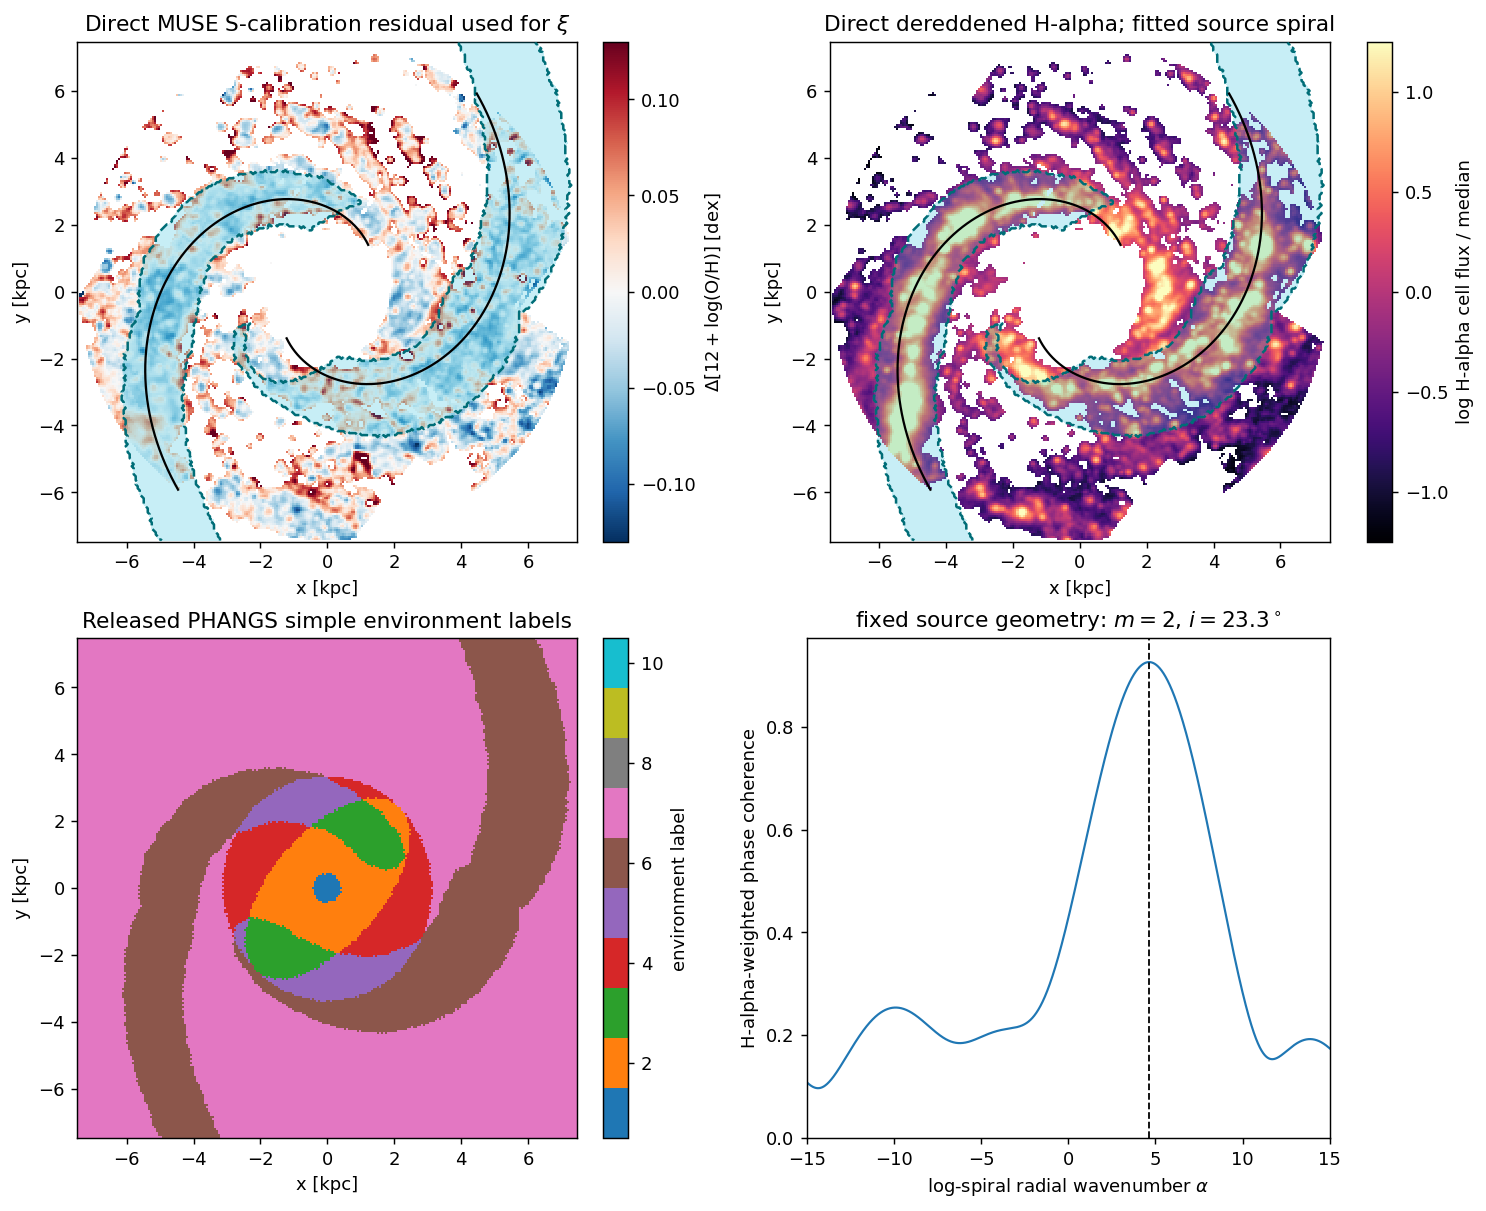

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11.2, 9.2), constrained_layout=True)

residual_image = axes[0, 0].pcolormesh(
    pixel_X, pixel_Y,
    np.where(pixel_valid_grid, pixel_residual_centered_grid, np.nan),
    shading="nearest", cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-0.13, vcenter=0.0, vmax=0.13),
)
axes[0, 0].set_title(r"Direct MUSE S-calibration residual used for $\xi$")
fig.colorbar(
    residual_image, ax=axes[0, 0],
    label=r"$\Delta[12+\log({\rm O/H})]$ [dex]",
)

halpha_plot = np.full(pixel_X.shape, np.nan)
halpha_plot[source_valid_grid] = (
    np.log10(source_halpha_flux) - np.median(np.log10(source_halpha_flux))
)
halpha_image = axes[0, 1].pcolormesh(
    pixel_X, pixel_Y, halpha_plot, shading="nearest", cmap="magma",
    vmin=-1.25, vmax=1.25,
)
arm_mask_grid = np.isin(environment_label_grid, [5, 6])
spiral_radius = np.linspace(R_MIN_KPC, R_MAX_KPC, 1200)
for axis in axes[0]:
    axis.contourf(
        pixel_X, pixel_Y, arm_mask_grid.astype(float), levels=[0.5, 1.5],
        colors=["#00b4d8"], alpha=0.22, zorder=4,
    )
    axis.contour(
        pixel_X, pixel_Y, arm_mask_grid.astype(float), levels=[0.5],
        colors="#006d77", linestyles="--", linewidths=1.4, zorder=5,
    )
    for arm_index in range(m_arms):
        spiral_phi = (
            spiral_alpha * np.log(spiral_radius / r_ref_kpc)
            + theta0 - 2.0 * np.pi * arm_index
        ) / m_arms
        axis.plot(
            spiral_radius * np.cos(spiral_phi),
            spiral_radius * np.sin(spiral_phi),
            color="black", ls="-", lw=1.25, zorder=6,
        )
axes[0, 1].set_title("Direct dereddened H-alpha; fitted source spiral")
fig.colorbar(
    halpha_image, ax=axes[0, 1],
    label="log H-alpha cell flux / median",
)

environment_image = axes[1, 0].pcolormesh(
    pixel_X, pixel_Y, environment_label_grid, shading="nearest",
    cmap="tab10", vmin=0.5, vmax=10.5,
)
axes[1, 0].set_title("Released PHANGS simple environment labels")
fig.colorbar(environment_image, ax=axes[1, 0], label="environment label")

axes[1, 1].plot(
    alpha_grid, spiral_trials[m_arms - 1]["coherence_curve"], lw=1.2,
)
axes[1, 1].axvline(spiral_alpha, color="black", ls="--", lw=1.0)
axes[1, 1].set_xlim(alpha_grid[0], alpha_grid[-1])
axes[1, 1].set_ylim(0.0, max(0.5, 1.05 * spiral_fit["coherence"]))
axes[1, 1].set_xlabel(r"log-spiral radial wavenumber $\alpha$")
axes[1, 1].set_ylabel("H-alpha-weighted phase coherence")
axes[1, 1].set_title(
    fr"fixed source geometry: $m={m_arms}$, $i={pitch_angle_deg:.1f}^\circ$"
)


for axis in axes.ravel():
    if axis is not axes[1, 1]:
        axis.set_aspect("equal")
        axis.set_xlabel("x [kpc]")
        axis.set_ylabel("y [kpc]")

fig.savefig(OUTPUT_DIR / "ngc1566_phangs_morphology.png", bbox_inches="tight")
display_figure(fig)


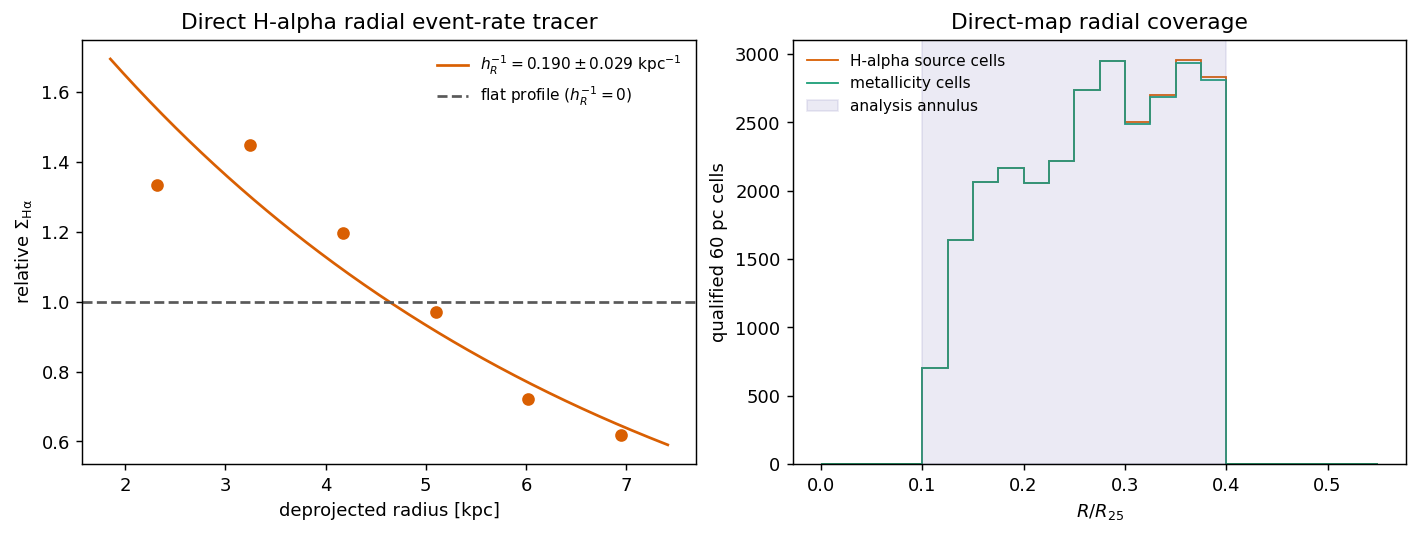

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.0), constrained_layout=True)
rate_radius_kpc = rate_centres_r25 * R25_KPC
normalised_rate = rate_surface_density / np.exp(
    np.mean(np.log(rate_surface_density[positive_rate_bins]))
)
axes[0].scatter(rate_radius_kpc[positive_rate_bins],
                normalised_rate[positive_rate_bins], color="#d95f02", zorder=3)
radial_plot = np.linspace(R_MIN_KPC, R_MAX_KPC, 300)
axes[0].plot(
    radial_plot,
    np.exp(rate_log_slope_halpha * (radial_plot - np.mean(rate_radius_kpc))),
    color="#d95f02",
    label=fr"$h_R^{{-1}}={-rate_log_slope_halpha:.3f}\pm{rate_log_slope_halpha_error:.3f}$ kpc$^{{-1}}$",
)
axes[0].axhline(1.0, color="0.35", ls="--", label=r"flat profile ($h_R^{-1}=0$)")
axes[0].set_xlabel("deprojected radius [kpc]")
axes[0].set_ylabel(r"relative $\Sigma_{\rm H\alpha}$")
axes[0].set_title("Direct H-alpha radial event-rate tracer")
axes[0].legend(frameon=False, fontsize=8.5)

coverage_edges = np.arange(0.0, 0.551, 0.025)
metallicity_counts, _ = np.histogram(r_r25, coverage_edges)
source_counts, _ = np.histogram(source_r_kpc / R25_KPC, coverage_edges)
axes[1].stairs(source_counts, coverage_edges, color="#d95f02",
               label="H-alpha source cells")
axes[1].stairs(metallicity_counts, coverage_edges, color="#1b9e77",
               label="metallicity cells")
axes[1].axvspan(R_MIN_R25, R_MAX_R25, color="#7570b3", alpha=0.14,
                label="analysis annulus")
axes[1].set_xlabel(r"$R/R_{25}$")
axes[1].set_ylabel("qualified 60 pc cells")
axes[1].set_title("Direct-map radial coverage")
axes[1].legend(frameon=False, fontsize=8.5)

fig.savefig(OUTPUT_DIR / "ngc1566_phangs_radial_selection.png",
            bbox_inches="tight")
display_figure(fig)


## 4. Exact finite-window statistic and observational transfer

The metallicity field entering the statistic is the direct $S$-calibration
map above after independent 0.2 kpc annular means have been removed.  The
zero-padded FFT computes the numerator, symmetric endpoint second moment, and
valid pair count for every grid lag.  Because both lag orientations are
included, the final counts are divided by two to report unordered pairs.

Uncertainty combines a 48-block spatial jackknife with line-flux Monte Carlo.
The Monte Carlo also estimates, bin by bin, how much correlated measurement
noise contributes to the numerator and endpoint second moment.  This fixed
transfer is applied to both KT18 and KTZ + isotropic C_NP without adding another free
parameter.  The analytic Li21 Gaussian beam correction is applied separately
to the theoretical injection width.


In [7]:
separation_edges = np.arange(
    0.5 * PIXEL_SIZE_KPC,
    5.0 + 0.5 * PIXEL_SIZE_KPC + 1.0e-9,
    PIXEL_SIZE_KPC,
)
separation_centres = 0.5 * (separation_edges[:-1] + separation_edges[1:])
n_bins = len(separation_centres)

lag_y = np.arange(-(pixel_X.shape[0] - 1), pixel_X.shape[0]) * PIXEL_SIZE_KPC
lag_x = np.arange(-(pixel_X.shape[1] - 1), pixel_X.shape[1]) * PIXEL_SIZE_KPC
lag_X, lag_Y = np.meshgrid(lag_x, lag_y)
lag_R = np.hypot(lag_X, lag_Y)
lag_bin = np.digitize(lag_R.ravel(), separation_edges) - 1
valid_lag_bin = (lag_bin >= 0) & (lag_bin < n_bins) & (lag_R.ravel() > 0)


def fft_pair_sums(values: np.ndarray, valid: np.ndarray):
    """Exact ordered-pair sums on a finite, non-periodic masked grid."""
    mask = valid.astype(float)
    field = np.where(valid, values, 0.0)
    power = field**2
    pair_grid = fftconvolve(mask, mask[::-1, ::-1], mode="full")
    numerator_grid = fftconvolve(field, field[::-1, ::-1], mode="full")
    endpoint_grid = 0.5 * (
        fftconvolve(power, mask[::-1, ::-1], mode="full")
        + fftconvolve(mask, power[::-1, ::-1], mode="full")
    )
    bins = lag_bin[valid_lag_bin]
    counts = np.bincount(
        bins, weights=pair_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    numerator = np.bincount(
        bins, weights=numerator_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    endpoint = np.bincount(
        bins, weights=endpoint_grid.ravel()[valid_lag_bin], minlength=n_bins
    )
    return numerator, endpoint, counts


def fft_pair_product_statistic(
    region_mask: np.ndarray | None = None,
    centre_residual: bool = True,
    metallicity_values: np.ndarray | None = None,
):
    """Li21 detrending plus the validation-matched exhaustive estimator."""
    if region_mask is None:
        region_mask = np.ones(pixel_X.shape, dtype=bool)
    if metallicity_values is None:
        metallicity_values = metallicity_grid
    valid = pixel_valid_grid & region_mask & np.isfinite(metallicity_values)
    residual_grid, _ = annular_residual_map(metallicity_values, valid)
    valid &= np.isfinite(residual_grid)
    residual_mean = float(np.mean(residual_grid[valid]))
    if centre_residual:
        residual_grid = residual_grid - residual_mean
    numerator, endpoint, ordered_counts = fft_pair_sums(residual_grid, valid)
    xi = np.divide(
        numerator, endpoint, out=np.full(n_bins, np.nan), where=endpoint > 0
    )
    unordered_counts = np.rint(0.5 * ordered_counts).astype(np.int64)
    numerator_mean = np.divide(
        numerator, ordered_counts, out=np.full(n_bins, np.nan),
        where=ordered_counts > 0,
    )
    endpoint_mean = np.divide(
        endpoint, ordered_counts, out=np.full(n_bins, np.nan),
        where=ordered_counts > 0,
    )
    return (xi, unordered_counts, residual_mean, numerator_mean,
            endpoint_mean, residual_grid)


(xi_observed, pair_counts, residual_mean, observed_numerator_mean,
 observed_endpoint_mean, observed_residual_grid) = fft_pair_product_statistic()
xi_uncentred = fft_pair_product_statistic(centre_residual=False)[0]


def delete_one_block_jackknife(block_label_grid: np.ndarray):
    labels = np.unique(block_label_grid[pixel_valid_grid])
    curves = []
    means = []
    for label in labels:
        retained = block_label_grid != label
        curve, _, mean_value, _, _, _ = fft_pair_product_statistic(retained)
        curves.append(curve)
        means.append(mean_value)
    curves = np.asarray(curves)
    means = np.asarray(means)
    factor = (len(labels) - 1.0) / len(labels)
    difference = np.nan_to_num(curves - np.nanmean(curves, axis=0), nan=0.0)
    covariance = factor * difference.T @ difference
    mean_error = float(np.sqrt(factor * np.sum((means - np.mean(means))**2)))
    return curves, covariance, mean_error


azimuth_12_grid = np.floor(pixel_PHI / (2.0 * np.pi) * 12).astype(int)
radial_block_edges = np.sqrt(np.linspace(R_MIN_KPC**2, R_MAX_KPC**2, 5))
radial_block_grid = np.clip(
    np.digitize(pixel_R, radial_block_edges) - 1, 0, 3
)
spatial_48_grid = 12 * radial_block_grid + azimuth_12_grid

sector_curves, sector_covariance, sector_mean_error = (
    delete_one_block_jackknife(azimuth_12_grid)
)
jackknife_curves, jackknife_covariance, residual_mean_error = (
    delete_one_block_jackknife(spatial_48_grid)
)
n_jackknife = len(np.unique(spatial_48_grid[pixel_valid_grid]))

# Re-evaluate the complete nonlinear abundance and detrending pipeline for
# every line-flux Monte Carlo map.  Keep the conservative nominal selection
# fixed; rare non-finite draws are replaced by the nominal value before the
# statistic is formed.
measurement_curves = np.empty((N_FLUX_MC, n_bins))
noise_numerator_means = np.empty((N_FLUX_MC, n_bins))
noise_endpoint_means = np.empty((N_FLUX_MC, n_bins))
for draw_index in range(N_FLUX_MC):
    draw_map = np.asarray(metallicity_mc_grid[draw_index], dtype=float)
    draw_map = np.where(np.isfinite(draw_map), draw_map, metallicity_grid)
    measurement_curves[draw_index] = fft_pair_product_statistic(
        metallicity_values=draw_map
    )[0]
    noise_map = draw_map - metallicity_grid
    noise_residual, _ = annular_residual_map(noise_map, pixel_valid_grid)
    noise_numerator, noise_endpoint, noise_counts = fft_pair_sums(
        noise_residual, pixel_valid_grid & np.isfinite(noise_residual)
    )
    noise_numerator_means[draw_index] = np.divide(
        noise_numerator, noise_counts, out=np.zeros(n_bins),
        where=noise_counts > 0,
    )
    noise_endpoint_means[draw_index] = np.divide(
        noise_endpoint, noise_counts, out=np.zeros(n_bins),
        where=noise_counts > 0,
    )

measurement_covariance = np.cov(measurement_curves, rowvar=False, ddof=1)
noise_numerator_mean = np.nanmean(noise_numerator_means, axis=0)
noise_endpoint_mean = np.nanmean(noise_endpoint_means, axis=0)
signal_endpoint_mean = np.clip(
    observed_endpoint_mean - noise_endpoint_mean, 0.0, None
)
observation_signal_fraction = np.divide(
    signal_endpoint_mean, observed_endpoint_mean,
    out=np.ones(n_bins), where=observed_endpoint_mean > 0,
)
observation_signal_fraction = np.clip(observation_signal_fraction, 0.05, 1.0)
observation_noise_bias = np.divide(
    noise_numerator_mean, observed_endpoint_mean,
    out=np.zeros(n_bins), where=observed_endpoint_mean > 0,
)


from scripts.phangs_annular_transfer import (
    apply_annular_detrending_transfer,
    load_or_build_annular_detrending_transfer,
    projected_numerator_and_denominator,
)

annular_transfer_path = (
    OUTPUT_DIR / "ngc1566_annular_detrending_transfer.npz"
)
annular_detrending_transfer = load_or_build_annular_detrending_transfer(
    annular_transfer_path, pixel_valid_grid, pixel_R, PIXEL_SIZE_KPC,
    separation_edges, separation_centres, ANNULUS_WIDTH_KPC,
)


def apply_observation_transfer(intrinsic_xi: np.ndarray) -> np.ndarray:
    """Apply annular detrending, then fixed correlated-noise transfer."""
    detrended_xi = apply_annular_detrending_transfer(
        intrinsic_xi, annular_detrending_transfer, zero_lag=1.0,
    )
    return (observation_signal_fraction * detrended_xi
            + observation_noise_bias)


def apply_observation_transfer_components(
    intrinsic_components: dict[str, np.ndarray],
) -> dict[str, np.ndarray]:
    """Project KTZ components with one common post-detrending variance."""
    intrinsic_total = sum(intrinsic_components.values())
    _, projected_denominator = projected_numerator_and_denominator(
        intrinsic_total, annular_detrending_transfer, zero_lag=1.0,
    )
    first_bin_total = float(intrinsic_total[0])
    if not np.isfinite(first_bin_total) or abs(first_bin_total) < 1.0e-12:
        zero_lag_shares = {name: 0.25 for name in intrinsic_components}
    else:
        zero_lag_shares = {
            name: float(values[0] / first_bin_total)
            for name, values in intrinsic_components.items()
        }
    share_sum = sum(zero_lag_shares.values())
    zero_lag_shares = {
        name: value / share_sum for name, value in zero_lag_shares.items()
    }
    projected = {}
    for name, values in intrinsic_components.items():
        projected_numerator, _ = projected_numerator_and_denominator(
            values, annular_detrending_transfer,
            zero_lag=zero_lag_shares[name],
        )
        projected[name] = observation_signal_fraction * np.divide(
            projected_numerator, projected_denominator,
            out=np.full_like(projected_numerator, np.nan),
            where=projected_denominator > 0.0,
        )
    return projected


total_covariance_raw = jackknife_covariance + measurement_covariance
xi_jackknife_error = np.sqrt(
    np.clip(np.diag(total_covariance_raw), 0.0, None)
)
xi_sector_error = np.sqrt(np.clip(np.diag(sector_covariance), 0.0, None))
xi_measurement_error = np.sqrt(
    np.clip(np.diag(measurement_covariance), 0.0, None)
)

fit_mask = (
    (separation_centres <= 5.0)
    & (pair_counts > 0)
    & np.isfinite(xi_observed)
    & np.all(np.isfinite(jackknife_curves), axis=0)
    & np.all(np.isfinite(measurement_curves), axis=0)
)
fit_indices = np.where(fit_mask)[0]
fit_covariance_raw = total_covariance_raw[np.ix_(fit_indices, fit_indices)]
covariance_shrinkage = 0.35
systematic_floor = 0.010
fit_covariance = (
    (1.0 - covariance_shrinkage) * fit_covariance_raw
    + covariance_shrinkage * np.diag(np.diag(fit_covariance_raw))
    + systematic_floor**2 * np.eye(len(fit_indices))
)
fit_cholesky = np.linalg.cholesky(fit_covariance)
np.savez_compressed(  # consumed by the exact-window joint stage (scripts/ktz_exact_window.py)
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_fit_covariance.npz",
    covariance=fit_covariance, raw_covariance=fit_covariance_raw,
    fit_indices=fit_indices, covariance_shrinkage=covariance_shrinkage,
    systematic_floor=systematic_floor,
)
covariance_reference_operator = np.linalg.solve(
    fit_covariance, fit_covariance_raw
)
regularised_chi2_reference_mean = float(
    np.trace(covariance_reference_operator)
)
regularised_chi2_reference_second_trace = float(
    np.trace(covariance_reference_operator @ covariance_reference_operator)
)
regularised_chi2_reference_effective_dof = float(
    regularised_chi2_reference_mean**2
    / regularised_chi2_reference_second_trace
)
fit_covariance_effective_rank = float(
    np.trace(fit_covariance)**2 / np.trace(fit_covariance @ fit_covariance)
)
print(
    'Covariance diagnostics: raw rank='
    f'{np.linalg.matrix_rank(fit_covariance_raw)}/{len(fit_indices)}, '
    f'fit-covariance participation rank={fit_covariance_effective_rank:.1f}, '
    f'regularised chi2 reference mean={regularised_chi2_reference_mean:.1f}, '
    f'Satterthwaite dof={regularised_chi2_reference_effective_dof:.1f}'
)

covariance_diagnostics = Table({
    "r_kpc": separation_centres,
    "pair_count": pair_counts,
    "xi_centered": xi_observed,
    "xi_uncentered": xi_uncentred,
    "centered_minus_uncentered": xi_observed - xi_uncentred,
    "total_error": xi_jackknife_error,
    "spatial_48_jackknife_error": np.sqrt(
        np.clip(np.diag(jackknife_covariance), 0.0, None)
    ),
    "line_flux_mc_error": xi_measurement_error,
    "azimuth_12_jackknife_error": xi_sector_error,
    "noise_signal_fraction": observation_signal_fraction,
    "noise_additive_bias": observation_noise_bias,
})
covariance_diagnostics.write(
    OUTPUT_DIR / "ngc1566_residual_covariance_diagnostics.csv",
    format="ascii.csv", overwrite=True,
)

annulus_sensitivity_rows = []
for annulus_name, lower_r25, upper_r25 in (
    ("R10_35", 0.10, 0.35),
    ("R10_40_primary", 0.10, 0.40),
    ("R15_35", 0.15, 0.35),
    ("R15_40", 0.15, 0.40),
):
    annulus_mask = (
        (pixel_R / R25_KPC >= lower_r25)
        & (pixel_R / R25_KPC <= upper_r25)
    )
    annulus_curve, annulus_counts, annulus_mean, _, _, _ = (
        fft_pair_product_statistic(annulus_mask)
    )
    annulus_sensitivity_rows.extend([
        (annulus_name, lower_r25, upper_r25,
         int(np.sum(pixel_valid_grid & annulus_mask)), annulus_mean,
         separation_centres[index], annulus_counts[index], annulus_curve[index])
        for index in range(n_bins)
    ])
Table(
    rows=annulus_sensitivity_rows,
    names=("annulus", "rmin_r25", "rmax_r25", "n_pixels", "residual_mean",
           "r_kpc", "pair_count", "xi_centered"),
).write(OUTPUT_DIR / "ngc1566_annulus_sensitivity.csv",
        format="ascii.csv", overwrite=True)


Covariance diagnostics: raw rank=83/83, fit-covariance participation rank=6.1, regularised chi2 reference mean=11.9, Satterthwaite dof=11.0


In [8]:
# Compress every unordered pair into deterministic separation/radius cells.
# The arbitrary mask is sampled exactly at both endpoints and on a half-pixel
# grid at every possible pair midpoint; no pair or arm-shape fit is sampled.
from scripts.phangs_pair_geometry import compress_regular_grid_template_pairs

n_pixels = len(r_kpc)
window_signature = hashlib.sha256(np.column_stack((
    x_kpc, y_kpc, metal_residual_centered
)).tobytes()).hexdigest()
pair_separation_subbins = 12
pair_midpoint_radial_edges = np.linspace(0.0, R_MAX_KPC, 257)

pair_geometry_signature = hashlib.sha256(json.dumps({
    "version": 2,
    "window": window_signature,
    "environment_mask": environment_mask_hash,
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "pixel_size_kpc": PIXEL_SIZE_KPC,
    "separation_edges": separation_edges.tolist(),
    "separation_subbins": pair_separation_subbins,
    "midpoint_radial_edges": pair_midpoint_radial_edges.tolist(),
}, sort_keys=True).encode()).hexdigest()
pair_geometry_path = (
    OUTPUT_DIR / "ngc1566_muse_scal_exhaustive_pair_geometry.npz"
)

pair_geometry_loaded = False
if pair_geometry_path.exists():
    with np.load(pair_geometry_path, allow_pickle=False) as cached:
        if str(cached["signature"].item()) == pair_geometry_signature:
            pair_geometry = {
                name: cached[name] for name in cached.files
                if name != "signature"
            }
            pair_geometry_loaded = True

if not pair_geometry_loaded:
    pair_geometry = compress_regular_grid_template_pairs(
        valid=pixel_valid_grid,
        x_grid=pixel_X,
        y_grid=pixel_Y,
        source_modulation_grid=source_modulation_grid,
        midpoint_modulation_grid=midpoint_source_modulation_grid,
        separation_edges=separation_edges,
        radial_edges=pair_midpoint_radial_edges,
        separation_subbins=pair_separation_subbins,
    )
    np.savez_compressed(
        pair_geometry_path,
        signature=np.asarray(pair_geometry_signature),
        **pair_geometry,
    )
else:
    print(f"Loaded matching exhaustive pair geometry: {pair_geometry_path.name}")

pair_counts_geometry = np.rint(np.bincount(
    pair_geometry["output_bin"],
    weights=pair_geometry["counts"],
    minlength=n_bins,
)).astype(np.int64)
if not np.array_equal(pair_counts_geometry, pair_counts):
    raise RuntimeError(
        "FFT and exhaustive compressed pair counts disagree; check bin edges."
    )
pair_count_total = int(np.sum(pair_geometry["counts"]))

print(f"Face-on analysis pixels: {n_pixels:,}")
print(f"All unordered pairs with r < 5 kpc: {pair_count_total:,}")
print(f"Occupied fine pair cells: {len(pair_geometry['counts']):,}")
print(f"MCMC fit bins (0 < r < 5 kpc): {len(fit_indices)}")
print(f"Residual mean: {residual_mean:+.6f} +/- {residual_mean_error:.6f} dex")
print(
    "Median measurement-noise signal fraction: "
    f"{np.nanmedian(observation_signal_fraction[fit_indices]):.3f}"
)


Face-on analysis pixels: 27,451
All unordered pairs with r < 5 kpc: 127,771,527
Occupied fine pair cells: 178,540
MCMC fit bins (0 < r < 5 kpc): 83
Residual mean: -0.000000 +/- 0.000000 dex
Median measurement-noise signal fraction: 0.998


## 5. Seven-parameter transport inference on the direct MUSE window

The KTZ + isotropic C_NP calculation uses the exact set of direct-MUSE cells and all
their pairs within 5 kpc.  Its intrinsic components are
$C_{{\rm 2p},0}$, $C_{{\rm 2p},N}$, $C_{\rm M}$, and the optional isotropic appendix
$C_{\rm NP}$.  The local Li21 beam correction is applied to the kernel
coordinates, the annular-mean projector is applied on the finite pixel mask,
and the fixed correlated-noise transfer inferred above is applied
to the final normalised prediction.  No separate ``Poisson KTZ'' is fitted.


In [9]:
from scripts.phangs_template_ktz import (
    COMPONENT_ORDER,
    correlation_components_from_template_basis,
    correlation_from_template_basis,
    template_cnp_pair_basis_exact,
    template_pair_basis,
)


def ktz_pair_basis(
    ell_value: float, epsilon_value: float,
    rate_log_slope_values: float | np.ndarray, quadrature_nodes: int = 20,
) -> dict[str, np.ndarray]:
    del quadrature_nodes
    return template_pair_basis(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_value, epsilon_value, rate_log_slope_values,
    )


def ktz_cnp_pair_basis_exact(
    ell_value: float, epsilon_value: float, rate_log_slope_value: float,
    source_length: float, quadrature_nodes: int = 20,
) -> dict[str, np.ndarray]:
    return template_cnp_pair_basis_exact(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_value, epsilon_value, rate_log_slope_value, source_length,
        quadrature_nodes=quadrature_nodes,
    )


component_order = COMPONENT_ORDER
component_colors = {
    "CP0": "#7fc97f", "CPN": "#ffff99",
    "CM": "#fdc086", "CNP": "#beaed4",
}
component_labels = {
    "CP0": r"$C_{{\rm 2p},0}$", "CPN": r"$C_{{\rm 2p},N}$",
    "CM": r"$C_{\rm M}$", "CNP": r"$C_{\rm NP}$",
}


def correlation_components_from_basis(*args, **kwargs):
    return correlation_components_from_template_basis(*args, **kwargs)


def correlation_from_basis(*args, **kwargs):
    return correlation_from_template_basis(*args, **kwargs)


### 5.1 Full-pair KTZ emulator for the independent H-alpha spiral template

The connected term samples the H-alpha-derived spiral modulation at every
pair midpoint, while the mean-field term uses its values at both endpoints.
The fitted geometry and its first three harmonics are fixed before the
metallicity likelihood is evaluated.  The source template is treated in the
local-source limit, while the transport and C_NP kernels retain their full
parameter dependence.


In [10]:
from scripts.phangs_template_ktz import (
    CNP_BASIS_NAMES, PAIR_BASIS_NAMES,
    build_template_cnp_emulator, build_template_pair_emulator,
    interpolate_regular_basis,
)

basis_names = PAIR_BASIS_NAMES
FIXED_GAMMA_SCALE = 1.0
ETA_PRIOR_SIGMA = float(max(
    mask_contrast_amplitude_error / mask_contrast_amplitude, 0.35
))

ell_emulator_grid = np.geomspace(0.08, 3.20, 11)
epsilon_emulator_grid = np.geomspace(0.015, 0.90, 10)
rate_log_slope_emulator_grid = np.linspace(-0.35, 0.35, 5)
emulator_path = OUTPUT_DIR / "ngc1566_muse_scal_7p_ktz_full_pair_emulator.npz"
emulator_signature = hashlib.sha256(json.dumps({
  # NOTE: signature key names kept verbatim so cached emulators/chains stay valid
    "version": 5,
    "environment_mask": environment_mask_hash,
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "window": window_signature,
    "pixel_size_kpc": PIXEL_SIZE_KPC,
    "target_fwhm_kpc": TARGET_FWHM_KPC,
    "line_sn_min": LINE_SN_MIN,
    "separation_edges": separation_edges.tolist(),
    "ell_grid": ell_emulator_grid.tolist(),
    "epsilon_grid": epsilon_emulator_grid.tolist(),
    "eta_grid": rate_log_slope_emulator_grid.tolist(),
}, sort_keys=True).encode()).hexdigest()

emulator_loaded = False
if emulator_path.exists():
    with np.load(emulator_path, allow_pickle=False) as cached:
        if str(cached["signature"].item()) == emulator_signature:
            basis_grid = cached["basis_grid"]
            emulator_loaded = True
if not emulator_loaded:
    basis_grid = build_template_pair_emulator(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid,
    )
    np.savez_compressed(
        emulator_path, signature=np.asarray(emulator_signature),
        ell_grid=ell_emulator_grid, epsilon_grid=epsilon_emulator_grid,
        rate_log_slope_grid=rate_log_slope_emulator_grid, basis_names=np.asarray(basis_names),
        basis_grid=basis_grid, pair_count=np.asarray(pair_count_total),
    )
else:
    print(f"Loaded matching mask-template emulator: {emulator_path.name}")


def interpolate_basis(ell_value, epsilon_value, rate_log_slope_value):
    return interpolate_regular_basis(
        (ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid),
        (ell_value, epsilon_value, rate_log_slope_value), basis_grid, basis_names,
        (True, True, False),
    )


source_length_emulator_grid = np.geomspace(0.005, 2.50, 17)
cnp_basis_names = CNP_BASIS_NAMES
cnp_emulator_path = (
    OUTPUT_DIR / "ngc1566_muse_scal_7p_ktz_cnp_full_pair_emulator.npz"
)
cnp_emulator_signature = hashlib.sha256(json.dumps({
  # NOTE: signature key names kept verbatim so cached emulators/chains stay valid
    "version": 5,
    "environment_mask": environment_mask_hash,
    "mask_contrast_amplitude": mask_contrast_amplitude,
    "window": window_signature,
    "fine_bins_per_output_bin": pair_separation_subbins,
    "ell_grid": ell_emulator_grid.tolist(),
    "epsilon_grid": epsilon_emulator_grid.tolist(),
    "eta_grid": rate_log_slope_emulator_grid.tolist(),
    "source_length_grid": source_length_emulator_grid.tolist(),
    "quadrature_nodes": 14,
}, sort_keys=True).encode()).hexdigest()

cnp_emulator_loaded = False
if cnp_emulator_path.exists():
    with np.load(cnp_emulator_path, allow_pickle=False) as cached:
        if str(cached["signature"].item()) == cnp_emulator_signature:
            cnp_basis_grid = cached["basis_grid"]
            cnp_emulator_loaded = True
if not cnp_emulator_loaded:
    cnp_basis_grid = build_template_cnp_emulator(
        pair_geometry, pair_counts_geometry, n_bins, r_ref_kpc,
        ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid,
        source_length_emulator_grid, pair_separation_subbins,
        quadrature_nodes=14,
    )
    np.savez_compressed(
        cnp_emulator_path, signature=np.asarray(cnp_emulator_signature),
        ell_grid=ell_emulator_grid, epsilon_grid=epsilon_emulator_grid,
        rate_log_slope_grid=rate_log_slope_emulator_grid,
        source_length_grid=source_length_emulator_grid,
        basis_names=np.asarray(cnp_basis_names), basis_grid=cnp_basis_grid,
        pair_count=np.asarray(pair_count_total),
    )
else:
    print(f"Loaded physical mask-template C_NP emulator: {cnp_emulator_path.name}")


def interpolate_cnp_basis(
    ell_value, epsilon_value, rate_log_slope_value, source_length,
):
    return interpolate_regular_basis(
        (ell_emulator_grid, epsilon_emulator_grid, rate_log_slope_emulator_grid,
         source_length_emulator_grid),
        (ell_value, epsilon_value, rate_log_slope_value, source_length),
        cnp_basis_grid, cnp_basis_names, (True, True, False, True),
    )


Template emulator row 1/11


Template emulator row 2/11


Template emulator row 3/11


Template emulator row 4/11


Template emulator row 5/11


Template emulator row 6/11


... (12 outputs left out)

Template C_NP row 8/11


Template C_NP row 9/11


Template C_NP row 10/11


Template C_NP row 11/11


### 5.2 Seven-parameter reparameterised KTZ and KT18 ensemble MCMC

The arm-amplitude parameter $\eta$ multiplies the fixed H-alpha logarithmic-spiral
template.  The likelihood forward-models the annular detrending applied to
the abundance map; it does not fit an additive negative-tail offset.


In [11]:
# Seven free KTZ likelihood coordinates; the H-alpha event-rate
# calibration remains fixed only for the derived (kappa, t_star) conversion.
parameter_names = (
    "log_ell_star", "logit_epsilon", "log_beta", "log_eta", "rate_log_slope",
    "log_beta_A_src", "log_ell_src",
)
n_ktz_likelihood_parameters = len(parameter_names)


def logit(value: float | np.ndarray) -> float | np.ndarray:
    value = np.asarray(value)
    answer = np.log(value) - np.log1p(-value)
    return float(answer) if answer.ndim == 0 else answer


def logistic(value: float | np.ndarray) -> float | np.ndarray:
    value = np.asarray(value)
    answer = 1.0 / (1.0 + np.exp(-value))
    return float(answer) if answer.ndim == 0 else answer


legacy_parameter_bounds = np.asarray([
    np.log([0.05, 1.50]),      # kappa [kpc^2 Gyr^-1]
    np.log([0.05, 3.00]),      # t_star [Gyr]
    np.log([0.015, 0.25]),     # injection sigma [kpc]
    np.log([0.10, 2.50]),      # source-template multiplier eta (theory arm amplitude)
    [-0.35, 0.35],             # rate_log_slope = -1/h_R [kpc^-1] (theory scale length h_R)
    np.log([1.0e-2, 1.0e3]),   # A_src
    np.log([0.005, 2.50]),     # ell_src [kpc]
])
profile_modulation = source_modulation_grid[np.isfinite(source_modulation_grid)]
if profile_modulation.min() < 0.0:
    eta_positive_limit = 0.98 / abs(profile_modulation.min())
    legacy_parameter_bounds[3, 1] = min(
        legacy_parameter_bounds[3, 1], np.log(eta_positive_limit)
    )

epsilon_limits = np.asarray([
    epsilon_emulator_grid[0], epsilon_emulator_grid[-1]
])
parameter_bounds = np.asarray([
    np.log([ell_emulator_grid[0], ell_emulator_grid[-1]]),
    logit(epsilon_limits),
    np.log([1.0e-4, 1.0e4]),
    legacy_parameter_bounds[3],
    legacy_parameter_bounds[4],
    np.log([1.0e-6, 1.0e7]),
    np.log([source_length_emulator_grid[0], source_length_emulator_grid[-1]]),
])
mass_moment_factor = event_mass_mean**2 / event_mass_second


BEAM_SIGMA_KPC = TARGET_FWHM_KPC / 2.354820045


def observed_kernel_parameters(
    ell_value: float, epsilon_value: float,
) -> tuple[float, float]:
    """Li21 Gaussian-beam broadening for KT18/local-WKBJ KTZ kernels."""
    sigma_intrinsic2 = (epsilon_value * ell_value)**2
    diffusion_extent2 = ell_value**2 - sigma_intrinsic2
    sigma_observed2 = sigma_intrinsic2 + 0.5 * BEAM_SIGMA_KPC**2
    ell_observed = np.sqrt(sigma_observed2 + diffusion_extent2)
    epsilon_observed = np.sqrt(sigma_observed2) / ell_observed
    return float(ell_observed), float(epsilon_observed)


def physical_parameters(internal_parameters: np.ndarray) -> dict[str, float]:
    ell_value = float(np.exp(internal_parameters[0]))
    epsilon_value = float(logistic(internal_parameters[1]))
    beta_value = float(np.exp(internal_parameters[2]))
    eta = float(np.exp(internal_parameters[3]))
    rate_log_slope_value = float(internal_parameters[4])
    beta_a_src = float(np.exp(internal_parameters[5]))
    source_clustering_length = float(np.exp(internal_parameters[6]))

    sigma_value = epsilon_value * ell_value
    kappa_t_value = 0.5 * ell_value**2 * (1.0 - epsilon_value**2)
    gamma_reference = (
        gamma_area_mean / relative_rate_area_mean(rate_log_slope_value)
        * FIXED_GAMMA_SCALE
    )
    t_value = beta_value / (
        4.0 * np.pi * (gamma_reference * 1.0e3)
        * mass_moment_factor * kappa_t_value
    )
    kappa_value = kappa_t_value / t_value
    source_excess_amplitude = beta_a_src / beta_value
    source_length_ratio = source_clustering_length / ell_value
    return {
        "ell_star": ell_value,
        "epsilon": epsilon_value,
        "beta": beta_value,
        "gamma_scale": FIXED_GAMMA_SCALE,
        "eta": eta,
        "rate_log_slope": rate_log_slope_value,
        "inv_h_R": -rate_log_slope_value,  # theory scale length h_R: lambda ~ exp(-R/h_R)
        "beta_A_src": beta_a_src,
        "source_clustering_ratio": source_length_ratio,
        "source_excess_amplitude": source_excess_amplitude,
        "source_clustering_length": source_clustering_length,
        "kappa": kappa_value,
        "t_star": t_value,
        "sigma": sigma_value,
        "kappa_t_star": kappa_t_value,
        "gamma_ref": gamma_reference,
    }


def reparameterize_legacy_coordinates(
    legacy_parameters: np.ndarray,
) -> np.ndarray:
    kappa_value, t_value, sigma_value, eta = np.exp(
        legacy_parameters[:4]
    )
    rate_log_slope_value = float(legacy_parameters[4])
    source_excess_amplitude, source_clustering_length = np.exp(
        legacy_parameters[5:7]
    )
    ell_value = np.sqrt(sigma_value**2 + 2.0 * kappa_value * t_value)
    epsilon_value = sigma_value / ell_value
    gamma_reference = (
        gamma_area_mean / relative_rate_area_mean(rate_log_slope_value)
        * FIXED_GAMMA_SCALE
    )
    beta_value = (
        4.0 * np.pi * kappa_value * (gamma_reference * 1.0e3)
        * t_value**2 * mass_moment_factor
    )
    return np.asarray([
        np.log(ell_value), logit(epsilon_value), np.log(beta_value),
        np.log(eta), rate_log_slope_value,
        np.log(beta_value * source_excess_amplitude),
        np.log(source_clustering_length),
    ])


def _within_log_bounds(value: float, bounds: np.ndarray) -> bool:
    return bool(bounds[0] <= np.log(value) <= bounds[1])


def log_prior(internal_parameters: np.ndarray) -> float:
    if np.any(internal_parameters < parameter_bounds[:, 0]) or np.any(
        internal_parameters > parameter_bounds[:, 1]
    ):
        return -np.inf
    physical = physical_parameters(internal_parameters)
    legacy_values = (
        physical["kappa"], physical["t_star"], physical["sigma"],
        physical["eta"], physical["source_excess_amplitude"],
        physical["source_clustering_length"],
    )
    legacy_indices = (0, 1, 2, 3, 5, 6)
    if any(
        not _within_log_bounds(value, legacy_parameter_bounds[index])
        for value, index in zip(legacy_values, legacy_indices)
    ):
        return -np.inf
    if not (
        legacy_parameter_bounds[4, 0]
        <= physical["rate_log_slope"]
        <= legacy_parameter_bounds[4, 1]
    ):
        return -np.inf
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    if interpolate_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"]
    ) is None:
        return -np.inf
    if interpolate_cnp_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"],
        physical["source_clustering_length"],
    ) is None:
        return -np.inf

    log_jacobian = np.log(2.0) - np.log1p(physical["epsilon"])
    return float(
        log_jacobian
        - 0.5 * (np.log(physical["eta"]) / ETA_PRIOR_SIGMA)**2
        - 0.5 * ((physical["rate_log_slope"] - rate_log_slope_halpha) / rate_log_slope_halpha_error)**2
    )


def model_from_parameters(
    internal_parameters: np.ndarray,
) -> np.ndarray | None:
    """Return the complete seven-parameter KTZ prediction, including C_NP."""
    physical = physical_parameters(internal_parameters)
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    basis = interpolate_basis(ell_observed, epsilon_observed, physical["rate_log_slope"])
    cnp_basis = interpolate_cnp_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"],
        physical["source_clustering_length"],
    )
    if basis is None or cnp_basis is None:
        return None
    intrinsic = correlation_from_basis(
        basis, physical["beta"], physical["eta"],
        source_excess_amplitude=physical["source_excess_amplitude"],
        cnp_basis=cnp_basis,
    )
    return apply_observation_transfer(intrinsic)


def correlated_chi_square(model: np.ndarray) -> float:
    residual = xi_observed[fit_indices] - model[fit_indices]
    whitened = np.linalg.solve(fit_cholesky, residual)
    return float(whitened @ whitened)


def log_posterior(internal_parameters: np.ndarray) -> float:
    prior = log_prior(internal_parameters)
    if not np.isfinite(prior):
        return -np.inf
    model = model_from_parameters(internal_parameters)
    if model is None or not np.all(np.isfinite(model[fit_indices])):
        return -np.inf
    return prior - 0.5 * correlated_chi_square(model)


def stretch_move_mcmc(
    initial: np.ndarray, n_steps: int, rng: np.random.Generator,
    stretch_scale: float = 2.0, log_probability_function=log_posterior,
):
    """Minimal affine-invariant Goodman--Weare ensemble sampler."""
    positions = initial.copy()
    n_walkers, n_dimensions = positions.shape
    log_probability = np.asarray([
        log_probability_function(row) for row in positions
    ])
    chain = np.empty((n_steps, n_walkers, n_dimensions))
    log_probability_chain = np.empty((n_steps, n_walkers))
    accepted = np.zeros(n_walkers, dtype=int)
    proposed = np.zeros(n_walkers, dtype=int)
    all_indices = np.arange(n_walkers)
    for step in range(n_steps):
        for parity in (0, 1):
            active = all_indices[parity::2]
            complement = all_indices[1 - parity::2]
            partners = positions[rng.choice(complement, size=len(active))]
            z_value = (
                (stretch_scale - 1.0) * rng.random(len(active)) + 1.0
            )**2 / stretch_scale
            proposals = partners + z_value[:, None] * (
                positions[active] - partners
            )
            proposal_probability = np.asarray([
                log_probability_function(row) for row in proposals
            ])
            log_acceptance = (
                (n_dimensions - 1.0) * np.log(z_value)
                + proposal_probability - log_probability[active]
            )
            accept = np.log(rng.random(len(active))) < log_acceptance
            positions[active[accept]] = proposals[accept]
            log_probability[active[accept]] = proposal_probability[accept]
            accepted[active] += accept
            proposed[active] += 1
        chain[step] = positions
        log_probability_chain[step] = log_probability
    return chain, log_probability_chain, accepted / proposed


def split_rhat(chain: np.ndarray) -> np.ndarray:
    half = chain.shape[0] // 2
    split = np.concatenate([
        np.transpose(chain[:half], (1, 0, 2)),
        np.transpose(chain[-half:], (1, 0, 2)),
    ])
    n_samples = split.shape[1]
    within = np.mean(np.var(split, axis=1, ddof=1), axis=0)
    between = n_samples * np.var(np.mean(split, axis=1), axis=0, ddof=1)
    variance = (n_samples - 1.0) / n_samples * within + between / n_samples
    return np.sqrt(variance / within)


def integrated_time(chain: np.ndarray) -> np.ndarray:
    n_steps = chain.shape[0]
    times = np.ones(chain.shape[2])
    lag_normalisation = np.arange(n_steps, 0, -1)[:, None, None]
    series = chain - np.mean(chain, axis=0, keepdims=True)
    transform = np.fft.rfft(series, n=2 * n_steps, axis=0)
    autocovariance = np.fft.irfft(
        np.abs(transform)**2, axis=0
    )[:n_steps] / lag_normalisation
    autocorrelation = (
        np.mean(autocovariance, axis=1)
        / np.mean(autocovariance[0], axis=0)
    )
    for parameter_index in range(chain.shape[2]):
        parameter_autocorrelation = autocorrelation[:, parameter_index]
        paired = (
            parameter_autocorrelation[1:-1:2]
            + parameter_autocorrelation[2::2]
        )
        positive = np.where(paired <= 0)[0]
        n_pairs = int(positive[0]) if len(positive) else len(paired)
        times[parameter_index] = max(
            1.0,
            1.0 + 2.0 * np.sum(
                parameter_autocorrelation[1:2 * n_pairs + 1]
            ),
        )
    return times


def credible_interval(values: np.ndarray) -> np.ndarray:
    return np.percentile(values, [16.0, 50.0, 84.0])



mcmc_rng = np.random.default_rng(1566)
n_walkers = 64
n_candidate = 60_000
legacy_candidate = mcmc_rng.uniform(
    legacy_parameter_bounds[:, 0], legacy_parameter_bounds[:, 1],
    size=(n_candidate, len(parameter_names)),
)
candidate = np.asarray([
    reparameterize_legacy_coordinates(row) for row in legacy_candidate
])
physical_summary_spec = (
    ("ell_star", "kpc"), ("epsilon", "dimensionless"),
    ("beta", "dimensionless"), ("eta", "dimensionless"),
    ("rate_log_slope", "kpc-1"), ("inv_h_R", "kpc-1"), ("beta_A_src", "dimensionless"),
    ("source_clustering_ratio", "dimensionless"),
    ("source_excess_amplitude", "dimensionless"),
    ("source_clustering_length", "kpc"),
    ("kappa", "kpc2 Gyr-1"), ("t_star", "Gyr"),
    ("sigma", "kpc"), ("kappa_t_star", "kpc2"),
    ("gamma_ref", "Myr-1 kpc-2"),
)

n_mcmc_steps = 50_000
fit_data_hasher = hashlib.sha256()
for fit_array in (
    xi_observed[fit_indices], fit_covariance,
    observation_signal_fraction[fit_indices], observation_noise_bias[fit_indices],
    annular_detrending_transfer["numerator_matrix"],
    annular_detrending_transfer["denominator_matrix"],
):
    fit_data_hasher.update(np.ascontiguousarray(fit_array).tobytes())
fit_data_signature = fit_data_hasher.hexdigest()
ktz_cache_signature = hashlib.sha256(json.dumps({
  # NOTE: signature key names kept verbatim so cached emulators/chains stay valid
    "version": 2,
    "pair_emulator": emulator_signature,
    "cnp_emulator": cnp_emulator_signature,
    "fit_data": fit_data_signature,
    "legacy_bounds": legacy_parameter_bounds.tolist(),
    "arm_prior_sigma": ETA_PRIOR_SIGMA,
    "eta_halpha": rate_log_slope_halpha,
    "eta_halpha_error": rate_log_slope_halpha_error,
    "steps": 50_000,
    "burn": 10_000,
}, sort_keys=True).encode()).hexdigest()
ktz_chain_path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_transport_chain.npz"
ktz_cache_loaded = False
if ktz_chain_path.exists():
    with np.load(ktz_chain_path, allow_pickle=False) as cached:
        cached_signature = (
            str(cached["model_signature"].item())
            if "model_signature" in cached.files else None
        )
        # Compatibility path for a chain written by the immediately preceding
        # mask-template run, before cache signatures were added.
        dependency_time = max(
            emulator_path.stat().st_mtime_ns,
            cnp_emulator_path.stat().st_mtime_ns,
            pair_geometry_path.stat().st_mtime_ns,
        )
        legacy_current = (
            cached_signature is None
            and ktz_chain_path.stat().st_mtime_ns >= dependency_time
        )
        if cached_signature == ktz_cache_signature or legacy_current:
            mcmc_chain = cached["internal_chain"]
            mcmc_log_probability = cached["log_probability"]
            mcmc_acceptance = cached["acceptance_fraction"]
            n_burn_steps = int(cached["burn_steps"].item())
            rhat = cached["rhat"]
            autocorrelation_time = cached["autocorrelation_time"]
            effective_sample_size = cached["effective_sample_size"]
            ktz_cache_loaded = True

if not ktz_cache_loaded:
    candidate_log_probability = np.asarray([log_posterior(row) for row in candidate])
    finite_candidate = np.isfinite(candidate_log_probability)
    if finite_candidate.sum() < n_walkers:
        raise RuntimeError("Too few finite points to initialise the KTZ MCMC.")
    ranked_candidate = np.where(finite_candidate)[0][
        np.argsort(candidate_log_probability[finite_candidate])
    ]
    initial_walkers = candidate[ranked_candidate[-n_walkers:]]

    n_mcmc_steps = 50_000
    n_burn_steps = 10_000
    mcmc_chain, mcmc_log_probability, mcmc_acceptance = stretch_move_mcmc(
        initial_walkers, n_mcmc_steps, mcmc_rng
    )
    posterior_chain = mcmc_chain[n_burn_steps:]
    rhat = split_rhat(posterior_chain)
    autocorrelation_time = integrated_time(posterior_chain)
    effective_sample_size = (
        posterior_chain.shape[0] * posterior_chain.shape[1]
        / autocorrelation_time
    )
    posterior_log_samples = posterior_chain[::5].reshape(-1, len(parameter_names))
    physical_summary_spec = (
        ("ell_star", "kpc"), ("epsilon", "dimensionless"),
        ("beta", "dimensionless"), ("eta", "dimensionless"),
        ("rate_log_slope", "kpc-1"), ("inv_h_R", "kpc-1"), ("beta_A_src", "dimensionless"),
        ("source_clustering_ratio", "dimensionless"),
        ("source_excess_amplitude", "dimensionless"),
        ("source_clustering_length", "kpc"),
        ("kappa", "kpc2 Gyr-1"), ("t_star", "Gyr"),
        ("sigma", "kpc"), ("kappa_t_star", "kpc2"),
        ("gamma_ref", "Myr-1 kpc-2"),
    )
    posterior_samples = {
        name: np.asarray([
            physical_parameters(row)[name] for row in posterior_log_samples
        ])
        for name, _ in physical_summary_spec
    }
    posterior_summary = Table(
        names=("parameter", "unit", "p16", "median", "p84"),
        rows=[
            (name, unit, *credible_interval(posterior_samples[name]))
            for name, unit in physical_summary_spec
        ],
    )
    posterior_summary.write(
        OUTPUT_DIR / "ngc1566_transport_posterior.csv",
        format="ascii.csv", overwrite=True,
    )
    np.savez_compressed(
        OUTPUT_DIR / "ngc1566_transport_chain.npz",
        parameter_names=np.asarray(parameter_names),
        internal_chain=mcmc_chain,
        log_probability=mcmc_log_probability,
        acceptance_fraction=mcmc_acceptance,
        burn_steps=np.asarray(n_burn_steps),
        rhat=rhat,
        autocorrelation_time=autocorrelation_time,
        effective_sample_size=effective_sample_size,
        fixed_gamma_scale=np.asarray(FIXED_GAMMA_SCALE),
    )
else:
    print(f"Loaded compatible KTZ chain: {ktz_chain_path.name}")

# Continue only fits that fail the pre-declared split-Rhat threshold.
# The deterministic seed makes a cached 50,000-step run reproducibly
# extensible without discarding its already computed likelihood calls.
rhat_threshold = 1.05
extension_steps = 25_000
maximum_mcmc_steps = 150_000
while (
    np.max(rhat) > rhat_threshold
    and mcmc_chain.shape[0] < maximum_mcmc_steps
):
    previous_steps = mcmc_chain.shape[0]
    added_steps = min(extension_steps, maximum_mcmc_steps - previous_steps)
    continuation_rng = np.random.default_rng(
        1_000_000 + int(GALAXY_NAME[3:]) + previous_steps
    )
    extension_chain, extension_log_probability, extension_acceptance = (
        stretch_move_mcmc(
            mcmc_chain[-1], added_steps, continuation_rng
        )
    )
    mcmc_chain = np.concatenate((mcmc_chain, extension_chain), axis=0)
    mcmc_log_probability = np.concatenate((
        mcmc_log_probability, extension_log_probability
    ), axis=0)
    mcmc_acceptance = (
        previous_steps * mcmc_acceptance
        + added_steps * extension_acceptance
    ) / (previous_steps + added_steps)
    posterior_chain = mcmc_chain[n_burn_steps:]
    rhat = split_rhat(posterior_chain)
    autocorrelation_time = integrated_time(posterior_chain)
    effective_sample_size = (
        posterior_chain.shape[0] * posterior_chain.shape[1]
        / autocorrelation_time
    )
    print(
        f"Extended KTZ chain to {mcmc_chain.shape[0]:,} steps; "
        f"max split-Rhat = {np.max(rhat):.4f}"
    )
n_mcmc_steps = int(mcmc_chain.shape[0])
# If a chain reaches the pre-declared length cap after slow mode settling,
# increase burn-in on the fixed 25,000-step grid.  Select the earliest suffix
# satisfying the same split-Rhat threshold; no likelihood result is discarded
# selectively by parameter or walker.
if np.max(rhat) > rhat_threshold:
    for candidate_burn in range(
        extension_steps, mcmc_chain.shape[0] - extension_steps + 1,
        extension_steps,
    ):
        if candidate_burn <= n_burn_steps:
            continue
        candidate_chain = mcmc_chain[candidate_burn:]
        candidate_rhat = split_rhat(candidate_chain)
        if np.max(candidate_rhat) <= rhat_threshold:
            n_burn_steps = candidate_burn
            posterior_chain = candidate_chain
            rhat = candidate_rhat
            autocorrelation_time = integrated_time(posterior_chain)
            effective_sample_size = (
                posterior_chain.shape[0] * posterior_chain.shape[1]
                / autocorrelation_time
            )
            print(
                f"Raised burn-in to {n_burn_steps:,} steps; "
                f"max split-Rhat = {np.max(rhat):.4f}"
            )
            break
if np.max(rhat) > rhat_threshold:
    print(
        f"WARNING: max split-Rhat {np.max(rhat):.4f} remains above "
        f"{rhat_threshold:.2f} at the {maximum_mcmc_steps:,}-step cap."
    )

posterior_chain = mcmc_chain[n_burn_steps:]
posterior_log_samples = posterior_chain[::5].reshape(-1, len(parameter_names))
posterior_samples = {
    name: np.asarray([physical_parameters(row)[name] for row in posterior_log_samples])
    for name, _ in physical_summary_spec
}
posterior_summary = Table(
    names=("parameter", "unit", "p16", "median", "p84"),
    rows=[
        (name, unit, *credible_interval(posterior_samples[name]))
        for name, unit in physical_summary_spec
    ],
)
posterior_summary.write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_transport_posterior.csv",
    format="ascii.csv", overwrite=True,
)
np.savez_compressed(
    ktz_chain_path,
    model_signature=np.asarray(ktz_cache_signature),
    parameter_names=np.asarray(parameter_names),
    internal_chain=mcmc_chain,
    log_probability=mcmc_log_probability,
    acceptance_fraction=mcmc_acceptance,
    burn_steps=np.asarray(n_burn_steps),
    rhat=rhat,
    autocorrelation_time=autocorrelation_time,
    effective_sample_size=effective_sample_size,
    fixed_gamma_scale=np.asarray(FIXED_GAMMA_SCALE),
)
display(posterior_summary)
display(Table({
    "parameter": parameter_names,
    "Rhat": rhat,
    "tau_int_steps": autocorrelation_time,
    "effective_samples": effective_sample_size,
}))
print(f"Complete-KTZ mean MCMC acceptance fraction: {np.mean(mcmc_acceptance):.3f}")


# Independently fit KT18 in the same common transport coordinates.  Its prior
# is the analytic marginal of the log-uniform (kappa, t, sigma) prior over the
# unconstrained age coordinate.
kt18_parameter_names = ("log_ell_star", "logit_epsilon")
kt18_parameter_bounds = parameter_bounds[:2].copy()


def kt18_physical_parameters(
    internal_parameters: np.ndarray,
) -> dict[str, float]:
    return {
        "ell_star": float(np.exp(internal_parameters[0])),
        "epsilon": float(logistic(internal_parameters[1])),
    }


def kt18_log_prior(internal_parameters: np.ndarray) -> float:
    if np.any(internal_parameters < kt18_parameter_bounds[:, 0]) or np.any(
        internal_parameters > kt18_parameter_bounds[:, 1]
    ):
        return -np.inf
    physical = kt18_physical_parameters(internal_parameters)
    ell_value = physical["ell_star"]
    epsilon_value = physical["epsilon"]
    sigma_value = epsilon_value * ell_value
    if not _within_log_bounds(sigma_value, legacy_parameter_bounds[2]):
        return -np.inf
    kappa_t_value = 0.5 * ell_value**2 * (1.0 - epsilon_value**2)
    log_t_lower = max(
        legacy_parameter_bounds[1, 0],
        np.log(kappa_t_value) - legacy_parameter_bounds[0, 1],
    )
    log_t_upper = min(
        legacy_parameter_bounds[1, 1],
        np.log(kappa_t_value) - legacy_parameter_bounds[0, 0],
    )
    log_t_width = log_t_upper - log_t_lower
    if log_t_width <= 0.0:
        return -np.inf
    log_jacobian = np.log(2.0) - np.log1p(epsilon_value)
    return float(log_jacobian + np.log(log_t_width))


def i0_dimensionless(rho: np.ndarray, epsilon_value: float) -> np.ndarray:
    """Uniform KT18 overlap kernel in the manuscript's dimensionless units."""
    rho = np.asarray(rho, dtype=float)
    return 0.5 * (
        exp1(rho**2 / 4.0)
        - exp1(rho**2 / (4.0 * epsilon_value**2))
    )


def kt18_model_from_parameters(
    internal_parameters: np.ndarray,
) -> np.ndarray:
    physical = kt18_physical_parameters(internal_parameters)
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    intrinsic = i0_dimensionless(
        separation_centres / ell_observed, epsilon_observed
    ) / (-np.log(epsilon_observed))
    return apply_observation_transfer(intrinsic)


def kt18_log_posterior(internal_parameters: np.ndarray) -> float:
    prior = kt18_log_prior(internal_parameters)
    if not np.isfinite(prior):
        return -np.inf
    model = kt18_model_from_parameters(internal_parameters)
    return prior - 0.5 * correlated_chi_square(model)


kt18_candidate = candidate[:, :2]
kt18_rng = np.random.default_rng(18_000 + int(GALAXY_NAME[3:]))
kt18_n_walkers = 32
kt18_n_mcmc_steps = 15_000
kt18_n_burn_steps = 4_000
kt18_cache_signature = hashlib.sha256(json.dumps({
    "version": 1,
    "fit_data": fit_data_signature,
    "legacy_transport_bounds": legacy_parameter_bounds[:3].tolist(),
    "steps": 15_000,
    "burn": 4_000,
}, sort_keys=True).encode()).hexdigest()
kt18_chain_path = OUTPUT_DIR / f"{GALAXY_NAME.lower()}_kt18_transport_chain.npz"
kt18_cache_loaded = False
if kt18_chain_path.exists():
    with np.load(kt18_chain_path, allow_pickle=False) as cached:
        cached_signature = (
            str(cached["model_signature"].item())
            if "model_signature" in cached.files else None
        )
        if cached_signature == kt18_cache_signature:
            kt18_mcmc_chain = cached["internal_chain"]
            kt18_mcmc_log_probability = cached["log_probability"]
            kt18_mcmc_acceptance = cached["acceptance_fraction"]
            kt18_n_burn_steps = int(cached["burn_steps"].item())
            kt18_rhat = cached["rhat"]
            kt18_autocorrelation_time = cached["autocorrelation_time"]
            kt18_effective_sample_size = cached["effective_sample_size"]
            kt18_cache_loaded = True

if not kt18_cache_loaded:
    kt18_candidate_log_probability = np.asarray([
        kt18_log_posterior(row) for row in kt18_candidate
    ])
    finite_kt18_candidate = np.isfinite(kt18_candidate_log_probability)
    ranked_kt18_candidate = np.where(finite_kt18_candidate)[0][
        np.argsort(kt18_candidate_log_probability[finite_kt18_candidate])
    ]
    kt18_n_walkers = 32
    kt18_initial_walkers = kt18_candidate[
        ranked_kt18_candidate[-kt18_n_walkers:]
    ]
    kt18_n_mcmc_steps = 15_000
    kt18_n_burn_steps = 4_000
    (
        kt18_mcmc_chain,
        kt18_mcmc_log_probability,
        kt18_mcmc_acceptance,
    ) = stretch_move_mcmc(
        kt18_initial_walkers, kt18_n_mcmc_steps, kt18_rng,
        log_probability_function=kt18_log_posterior,
    )
    kt18_posterior_chain = kt18_mcmc_chain[kt18_n_burn_steps:]
    kt18_rhat = split_rhat(kt18_posterior_chain)
    kt18_autocorrelation_time = integrated_time(kt18_posterior_chain)
    kt18_effective_sample_size = (
        kt18_posterior_chain.shape[0] * kt18_posterior_chain.shape[1]
        / kt18_autocorrelation_time
    )
    kt18_posterior_log_samples = kt18_posterior_chain[::5].reshape(
        -1, len(kt18_parameter_names)
    )
    kt18_posterior_samples = {
        name: np.asarray([
            kt18_physical_parameters(row)[name]
            for row in kt18_posterior_log_samples
        ])
        for name in ("ell_star", "epsilon")
    }
    kt18_posterior_summary = Table(
        names=("parameter", "unit", "p16", "median", "p84"),
        rows=[
            ("ell_star", "kpc", *credible_interval(
                kt18_posterior_samples["ell_star"]
            )),
            ("epsilon", "dimensionless", *credible_interval(
                kt18_posterior_samples["epsilon"]
            )),
        ],
    )
    kt18_posterior_summary.write(
        OUTPUT_DIR / "ngc1566_kt18_transport_posterior.csv",
        format="ascii.csv", overwrite=True,
    )
    np.savez_compressed(
        OUTPUT_DIR / "ngc1566_kt18_transport_chain.npz",
        parameter_names=np.asarray(kt18_parameter_names),
        internal_chain=kt18_mcmc_chain,
        log_probability=kt18_mcmc_log_probability,
        acceptance_fraction=kt18_mcmc_acceptance,
        burn_steps=np.asarray(kt18_n_burn_steps),
        rhat=kt18_rhat,
        autocorrelation_time=kt18_autocorrelation_time,
        effective_sample_size=kt18_effective_sample_size,
    )
else:
    print(f"Loaded compatible KT18 chain: {kt18_chain_path.name}")

kt18_posterior_chain = kt18_mcmc_chain[kt18_n_burn_steps:]
kt18_posterior_log_samples = kt18_posterior_chain[::5].reshape(
    -1, len(kt18_parameter_names)
)
kt18_posterior_samples = {
    "ell_star": np.exp(kt18_posterior_log_samples[:, 0]),
    "epsilon": logistic(kt18_posterior_log_samples[:, 1]),
}
kt18_posterior_summary = Table(
    names=("parameter", "unit", "p16", "median", "p84"),
    rows=[
        ("ell_star", "kpc", *credible_interval(
            kt18_posterior_samples["ell_star"]
        )),
        ("epsilon", "dimensionless", *credible_interval(
            kt18_posterior_samples["epsilon"]
        )),
    ],
)
kt18_posterior_summary.write(
    OUTPUT_DIR / f"{GALAXY_NAME.lower()}_kt18_transport_posterior.csv",
    format="ascii.csv", overwrite=True,
)
np.savez_compressed(
    kt18_chain_path,
    model_signature=np.asarray(kt18_cache_signature),
    parameter_names=np.asarray(kt18_parameter_names),
    internal_chain=kt18_mcmc_chain,
    log_probability=kt18_mcmc_log_probability,
    acceptance_fraction=kt18_mcmc_acceptance,
    burn_steps=np.asarray(kt18_n_burn_steps),
    rhat=kt18_rhat,
    autocorrelation_time=kt18_autocorrelation_time,
    effective_sample_size=kt18_effective_sample_size,
)
display(kt18_posterior_summary)
display(Table({
    "parameter": kt18_parameter_names,
    "Rhat": kt18_rhat,
    "tau_int_steps": kt18_autocorrelation_time,
    "effective_samples": kt18_effective_sample_size,
}))
print(f"KT18 mean MCMC acceptance fraction: {np.mean(kt18_mcmc_acceptance):.3f}")


parameter,unit,p16,median,p84
str24,str13,float64,float64,float64
ell_star,kpc,0.10295538140289363,0.12028896727243993,0.14072091256763186
epsilon,dimensionless,0.22484547132710092,0.36952767672867176,0.5181486887060949
beta,dimensionless,0.4195071729729294,0.7913551394664726,1.4947209205273766
eta,dimensionless,0.45324367615488786,0.5594039126840373,0.6554078582281635
rate_log_slope,kpc-1,-0.2070018735207595,-0.1793348530701971,-0.1523141836714455
inv_h_R,kpc-1,0.15231418367144547,0.1793348530701971,0.2070018735207595
beta_A_src,dimensionless,0.037592279584747645,0.5108607224081149,67.44133740294805
source_clustering_ratio,dimensionless,0.07220972528013017,0.28840045373491907,3.8333414073736813
source_excess_amplitude,dimensionless,0.05673362242325698,0.7979793696250167,55.846429892142794


parameter,Rhat,tau_int_steps,effective_samples
str14,float64,float64,float64
log_ell_star,1.0104441369097847,380.85836286525864,6721.658888466329
logit_epsilon,1.0117194076859253,409.391123580873,6253.188827369106
log_beta,1.012289488308095,469.3126725282308,5454.785582944188
log_eta,1.0114030786812858,454.6736761701571,5630.411730812289
rate_log_slope,1.0073721386280499,251.69421869626385,10171.071919173964
log_beta_A_src,1.014565136256382,537.6831764634504,4761.168122904844
log_ell_src,1.0164744847557103,557.9829913937954,4587.953467193205


Complete-KTZ mean MCMC acceptance fraction: 0.268


parameter,unit,p16,median,p84
str8,str13,float64,float64,float64
ell_star,kpc,0.45182037679275844,0.5104570537117471,0.5784568343940747
epsilon,dimensionless,0.02786654446696535,0.032356895976769454,0.03820247956618352


parameter,Rhat,tau_int_steps,effective_samples
str13,float64,float64,float64
log_ell_star,1.0031342822674827,34.756019660920515,10127.7419979074
logit_epsilon,1.003757754352893,37.26475895384233,9445.92182753689


KT18 mean MCMC acceptance fraction: 0.676


### 5.3 Posterior-median fit and posterior uncertainty


In [12]:
n_prediction_draws = min(
    1500, len(posterior_log_samples), len(kt18_posterior_log_samples)
)
prediction_rng = np.random.default_rng(900_000 + int(GALAXY_NAME[3:]))
prediction_indices = prediction_rng.choice(
    len(posterior_log_samples), n_prediction_draws, replace=False
)
kt18_prediction_indices = prediction_rng.choice(
    len(kt18_posterior_log_samples), n_prediction_draws, replace=False
)
xi_full_ktz_draws = np.empty((n_prediction_draws, n_bins))
xi_kt18_draws = np.empty_like(xi_full_ktz_draws)
component_draws = {
    name: np.empty_like(xi_full_ktz_draws) for name in component_order
}
for output_index, sample_index in enumerate(prediction_indices):
    physical = physical_parameters(posterior_log_samples[sample_index])
    ell_observed, epsilon_observed = observed_kernel_parameters(
        physical["ell_star"], physical["epsilon"]
    )
    basis = interpolate_basis(ell_observed, epsilon_observed, physical["rate_log_slope"])
    cnp_basis = interpolate_cnp_basis(
        ell_observed, epsilon_observed, physical["rate_log_slope"],
        physical["source_clustering_length"],
    )
    intrinsic_components = correlation_components_from_basis(
        basis, physical["beta"], physical["eta"],
        physical["source_excess_amplitude"], cnp_basis,
    )
    components = apply_observation_transfer_components(intrinsic_components)
    for name in component_order:
        component_draws[name][output_index] = components[name]
    xi_full_ktz_draws[output_index] = (
        sum(components.values()) + observation_noise_bias
    )
for output_index, sample_index in enumerate(kt18_prediction_indices):
    xi_kt18_draws[output_index] = kt18_model_from_parameters(
        kt18_posterior_log_samples[sample_index]
    )

xi_kt18_interval = np.percentile(xi_kt18_draws, [16, 50, 84], axis=0)
xi_full_ktz_interval = np.percentile(
    xi_full_ktz_draws, [16, 50, 84], axis=0
)
component_intervals = {
    name: np.percentile(draws, [16, 50, 84], axis=0)
    for name, draws in component_draws.items()
}
delta_full_draws = xi_full_ktz_draws - xi_kt18_draws
delta_full_interval = np.percentile(delta_full_draws, [16, 50, 84], axis=0)
xi_kt18 = xi_kt18_interval[1]
xi_full_ktz = xi_full_ktz_interval[1]
delta_total = delta_full_interval[1]

# Select one joint posterior draw whose complete curve is closest to the
# pointwise posterior median in the fitted covariance metric.  Components
# from this single draw are exactly additive, unlike marginal medians.
representative_residual = (
    xi_full_ktz_draws[:, fit_indices] - xi_full_ktz[fit_indices][None, :]
)
representative_whitened = np.linalg.solve(
    fit_cholesky, representative_residual.T
)
representative_draw_index = int(np.argmin(
    np.sum(representative_whitened**2, axis=0)
))
xi_full_ktz_representative = xi_full_ktz_draws[representative_draw_index]
representative_components = {
    name: draws[representative_draw_index]
    for name, draws in component_draws.items()
}
if not np.allclose(
    xi_full_ktz_representative,
    sum(representative_components.values()) + observation_noise_bias,
    rtol=2.0e-12, atol=2.0e-12,
):
    raise RuntimeError("Joint representative component sum is inconsistent.")

# The plotted central curve is the pointwise posterior-predictive median.
# Retain one coordinate-median exact evaluation only as an emulator diagnostic.
median_internal_parameters = np.median(posterior_log_samples, axis=0)
median_physical = physical_parameters(median_internal_parameters)
median_ell_observed, median_epsilon_observed = observed_kernel_parameters(
    median_physical["ell_star"], median_physical["epsilon"]
)
median_basis_emulated = interpolate_basis(
    median_ell_observed, median_epsilon_observed, median_physical["rate_log_slope"],
)
median_cnp_basis_emulated = interpolate_cnp_basis(
    median_ell_observed, median_epsilon_observed, median_physical["rate_log_slope"],
    median_physical["source_clustering_length"],
)
median_basis_exact = ktz_pair_basis(
    median_ell_observed, median_epsilon_observed,
    median_physical["rate_log_slope"], quadrature_nodes=20,
)
median_cnp_basis_exact = ktz_cnp_pair_basis_exact(
    median_ell_observed, median_epsilon_observed,
    median_physical["rate_log_slope"], median_physical["source_clustering_length"],
    quadrature_nodes=20,
)
median_components_emulated = apply_observation_transfer_components(
    correlation_components_from_basis(
        median_basis_emulated, median_physical["beta"],
        median_physical["eta"],
        median_physical["source_excess_amplitude"],
        median_cnp_basis_emulated,
    )
)
median_components_exact = apply_observation_transfer_components(
    correlation_components_from_basis(
        median_basis_exact, median_physical["beta"],
        median_physical["eta"],
        median_physical["source_excess_amplitude"], median_cnp_basis_exact,
    )
)
median_xi_emulated = sum(median_components_emulated.values()) + observation_noise_bias
median_xi_exact = sum(median_components_exact.values()) + observation_noise_bias
emulator_max_error = float(np.nanmax(np.abs(
    median_xi_emulated - median_xi_exact
)))
median_fit_chi2 = correlated_chi_square(median_xi_exact)
indicative_fit_dof = max(
    1, len(fit_indices) - n_ktz_likelihood_parameters
)
median_fit_pvalue = float(chi2.sf(median_fit_chi2, indicative_fit_dof))
print(
    "Coordinate-median KTZ + isotropic C_NP emulator max |error|: "
    f"{emulator_max_error:.4f}"
)
print(
    "Coordinate-median correlated chi2 / indicative dof: "
    f"{median_fit_chi2:.1f} / {indicative_fit_dof} "
    f"(indicative p={median_fit_pvalue:.3f})"
)



# Report posterior medians as the primary fit summary.  The curve chi-square is
# evaluated for the pointwise posterior-predictive median used in the figures.
posterior_median_curve_chi2 = correlated_chi_square(xi_full_ktz)
kt18_posterior_median_curve_chi2 = correlated_chi_square(xi_kt18)
ktz_nominal_dof = max(1, len(fit_indices) - n_ktz_likelihood_parameters)
kt18_nominal_dof = max(1, len(fit_indices) - len(kt18_parameter_names))
ktz_posterior_median_curve_reduced_chi2 = (
    posterior_median_curve_chi2 / ktz_nominal_dof
)
kt18_posterior_median_curve_reduced_chi2 = (
    kt18_posterior_median_curve_chi2 / kt18_nominal_dof
)
ktz_covariance_calibrated_discrepancy = (
    posterior_median_curve_chi2 / regularised_chi2_reference_mean
)
kt18_covariance_calibrated_discrepancy = (
    kt18_posterior_median_curve_chi2 / regularised_chi2_reference_mean
)
ktz_posterior_medians = {
    name: float(np.median(values)) for name, values in posterior_samples.items()
}
kt18_posterior_medians = {
    name: float(np.median(values))
    for name, values in kt18_posterior_samples.items()
}
print(
    "Posterior-median KTZ + isotropic C_NP curve chi2 / indicative dof: "
    f"{posterior_median_curve_chi2:.1f} / {indicative_fit_dof}"
)
print(
    "Posterior-median KT18 curve chi2 / indicative dof: "
    f"{kt18_posterior_median_curve_chi2:.1f} / "
    f"{max(1, len(fit_indices) - len(kt18_parameter_names))}"
)
fit_summary_table = Table(rows=[
    (
        "KTZ + isotropic C_NP", n_ktz_likelihood_parameters, ktz_nominal_dof,
        posterior_median_curve_chi2,
        ktz_posterior_median_curve_reduced_chi2,
        regularised_chi2_reference_mean,
        ktz_covariance_calibrated_discrepancy,
        ktz_posterior_medians["ell_star"],
        ktz_posterior_medians["epsilon"],
        ktz_posterior_medians["beta"],
        ktz_posterior_medians["source_excess_amplitude"],
        ktz_posterior_medians["source_clustering_length"],
    ),
    (
        "KT18", len(kt18_parameter_names), kt18_nominal_dof,
        kt18_posterior_median_curve_chi2,
        kt18_posterior_median_curve_reduced_chi2,
        regularised_chi2_reference_mean,
        kt18_covariance_calibrated_discrepancy,
        kt18_posterior_medians["ell_star"],
        kt18_posterior_medians["epsilon"],
        np.nan, np.nan, np.nan,
    ),
], names=(
    "model", "n_parameters", "nominal_dof",
    "posterior_median_curve_chi2",
    "nominal_reduced_chi2_not_calibrated",
    "regularised_chi2_reference_mean",
    "covariance_calibrated_discrepancy",
    "median_ell_star_kpc", "median_epsilon", "median_beta_src",
    "median_source_excess_amplitude",
    "median_source_clustering_length_kpc",
))
fit_summary_table.write(
    OUTPUT_DIR / "ngc1566_ktz_fit_summary.csv",
    format="ascii.csv", overwrite=True,
)
display(fit_summary_table)

# Sensitivity of the same coordinate-median residual to block geometry and
# shrinkage.  These are diagnostics, not independently re-fitted posteriors.
median_fit_residual = xi_observed[fit_indices] - median_xi_exact[fit_indices]
covariance_sensitivity_rows = []
for covariance_name, raw_covariance in (
    ("spatial_48", jackknife_covariance),
    ("azimuth_12", sector_covariance),
):
    raw_fit = raw_covariance[np.ix_(fit_indices, fit_indices)]
    for shrinkage_value in (0.15, 0.35, 0.60):
        covariance_value = (
            (1.0 - shrinkage_value) * raw_fit
            + shrinkage_value * np.diag(np.diag(raw_fit))
            + systematic_floor**2 * np.eye(len(fit_indices))
        )
        whitened = np.linalg.solve(
            np.linalg.cholesky(covariance_value), median_fit_residual
        )
        covariance_sensitivity_rows.append((
            covariance_name, shrinkage_value,
            np.linalg.matrix_rank(raw_fit), float(whitened @ whitened),
        ))
covariance_sensitivity = Table(
    rows=covariance_sensitivity_rows,
    names=("blocks", "shrinkage", "raw_rank", "median_model_chi2"),
)
covariance_sensitivity.write(
    OUTPUT_DIR / "ngc1566_covariance_sensitivity.csv",
    format="ascii.csv", overwrite=True,
)
display(covariance_sensitivity)

def prepend_zero_anchor(values: np.ndarray, zero_value: float) -> np.ndarray:
    return np.concatenate((np.asarray([zero_value]), np.asarray(values)))


separation_with_zero = prepend_zero_anchor(separation_centres, 0.0)
xi_observed_with_zero = prepend_zero_anchor(xi_observed, 1.0)
xi_error_with_zero = prepend_zero_anchor(xi_jackknife_error, 0.0)
xi_kt18_median_with_zero = prepend_zero_anchor(xi_kt18, 1.0)
xi_ktz_median_with_zero = prepend_zero_anchor(xi_full_ktz, 1.0)
xi_kt18_interval_with_zero = np.concatenate((
    np.ones((3, 1)), xi_kt18_interval,
), axis=1)
xi_ktz_interval_with_zero = np.concatenate((
    np.ones((3, 1)), xi_full_ktz_interval,
), axis=1)
delta_interval_with_zero = np.concatenate((
    np.zeros((3, 1)), delta_full_interval,
), axis=1)

single_element_columns = {
    "r_kpc": separation_with_zero,
    "is_fixed_normalisation_anchor": np.concatenate((
        np.asarray([True]), np.zeros(n_bins, dtype=bool),
    )),
    "pair_count": prepend_zero_anchor(pair_counts, n_pixels).astype(int),
    "xi_observed": xi_observed_with_zero,
    "xi_jackknife_error": xi_error_with_zero,
    "xi_KT18_p16": xi_kt18_interval_with_zero[0],
    "xi_KT18_median": xi_kt18_interval_with_zero[1],
    "xi_KT18_p84": xi_kt18_interval_with_zero[2],
    "xi_KTZ_p16": xi_ktz_interval_with_zero[0],
    "xi_KTZ_median": xi_ktz_interval_with_zero[1],
    "xi_KTZ_p84": xi_ktz_interval_with_zero[2],
    "xi_KTZ_joint_representative": prepend_zero_anchor(
        xi_full_ktz_representative, 1.0
    ),
    "delta_KTZ_minus_KT18_p16": delta_interval_with_zero[0],
    "delta_KTZ_minus_KT18_median": delta_interval_with_zero[1],
    "delta_KTZ_minus_KT18_p84": delta_interval_with_zero[2],
    "observation_signal_fraction": prepend_zero_anchor(
        observation_signal_fraction, 1.0
    ),
    "observation_noise_bias": prepend_zero_anchor(
        observation_noise_bias, 0.0
    ),
}
for name in component_order:
    # The total correlation is fixed at unity at zero lag.  Component shares
    # are not inferred from an observed self-pair and are left undefined there.
    single_element_columns[f"xi_component_{name}_p16"] = prepend_zero_anchor(
        component_intervals[name][0], np.nan,
    )
    single_element_columns[f"xi_component_{name}_median"] = prepend_zero_anchor(
        component_intervals[name][1], np.nan,
    )
    single_element_columns[f"xi_component_{name}_p84"] = prepend_zero_anchor(
        component_intervals[name][2], np.nan,
    )
    single_element_columns[f"xi_component_{name}_joint_representative"] = (
        prepend_zero_anchor(representative_components[name], np.nan)
    )
    single_element_columns[
        f"xi_component_{name}_at_coordinate_median"
    ] = prepend_zero_anchor(median_components_exact[name], np.nan)
single_element_results = Table(single_element_columns)
single_element_results.write(
    OUTPUT_DIR / "ngc1566_xi_observed_and_models.csv",
    format="ascii.csv", overwrite=True,
)

morphology_summary.update({
    "inference": (
        "reparameterised affine-invariant KTZ + isotropic C_NP and independent KT18 "
        "ensemble MCMC"
    ),
    "ktz_internal_parameter_names": list(parameter_names),
    "ktz_n_free_parameters": n_ktz_likelihood_parameters,
    "fixed_gamma_scale": FIXED_GAMMA_SCALE,
    "fit_range_kpc": [0.0, 5.0],
    "zero_lag_anchor_fixed_to_unity": True,
    "n_fitted_positive_separation_bins": int(len(fit_indices)),
    "kt18_internal_parameter_names": list(kt18_parameter_names),
    "prior_measure": (
        "legacy physical prior with informative H-alpha priors on eta and rate_log_slope (h_R^-1), "
        "fixed s_gamma=1, and exact Jacobian; KT18 uses the same "
        "transport bounds"
    ),
    "mcmc_walkers": n_walkers,
    "mcmc_steps": n_mcmc_steps,
    "mcmc_burn_steps": n_burn_steps,
    "mcmc_mean_acceptance": float(np.mean(mcmc_acceptance)),
    "mcmc_max_rhat": float(np.max(rhat)),
    "kt18_mcmc_walkers": kt18_n_walkers,
    "kt18_mcmc_steps": kt18_n_mcmc_steps,
    "kt18_mcmc_burn_steps": kt18_n_burn_steps,
    "kt18_mcmc_mean_acceptance": float(np.mean(kt18_mcmc_acceptance)),
    "kt18_mcmc_max_rhat": float(np.max(kt18_rhat)),
    "full_pair_emulator_max_error_at_coordinate_median": emulator_max_error,
    "fit_covariance_raw_rank": int(np.linalg.matrix_rank(fit_covariance_raw)),
    "fit_covariance_effective_rank": fit_covariance_effective_rank,
    "regularised_chi2_reference_mean": regularised_chi2_reference_mean,
    "regularised_chi2_reference_effective_dof": (
        regularised_chi2_reference_effective_dof
    ),
    "coordinate_median_fit_chi2": median_fit_chi2,
    "indicative_fit_dof": indicative_fit_dof,
    "indicative_fit_pvalue": median_fit_pvalue,
    "complete_ktz_posterior_median_curve_chi2": (
        posterior_median_curve_chi2
    ),
    "complete_ktz_nominal_reduced_chi2": (
        ktz_posterior_median_curve_reduced_chi2
    ),
    "complete_ktz_covariance_calibrated_discrepancy": (
        ktz_covariance_calibrated_discrepancy
    ),
    "kt18_posterior_median_curve_chi2": (
        kt18_posterior_median_curve_chi2
    ),
    "kt18_nominal_reduced_chi2": (
        kt18_posterior_median_curve_reduced_chi2
    ),
    "kt18_covariance_calibrated_discrepancy": (
        kt18_covariance_calibrated_discrepancy
    ),
    "posterior_median_source_excess_amplitude": (
        ktz_posterior_medians["source_excess_amplitude"]
    ),
    "posterior_median_source_clustering_length_kpc": (
        ktz_posterior_medians["source_clustering_length"]
    ),
    "kt18_posterior_median_ell_star_kpc": (
        kt18_posterior_medians["ell_star"]
    ),
    "kt18_posterior_median_epsilon": (
        kt18_posterior_medians["epsilon"]
    ),
    "residual_mean_dex": residual_mean,
    "observation_noise_transfer": "fixed from 200 line-flux MC maps",
    "median_noise_signal_fraction": float(np.nanmedian(
        observation_signal_fraction[fit_indices]
    )),
    "residual_mean_jackknife_error_dex": residual_mean_error,
    "maximum_centering_change_in_xi": float(np.nanmax(np.abs(
        xi_observed - xi_uncentred
    ))),
    "posterior_intervals_p16_median_p84": {
        name: credible_interval(values).tolist()
        for name, values in posterior_samples.items()
    },
    "kt18_posterior_intervals_p16_median_p84": {
        name: credible_interval(values).tolist()
        for name, values in kt18_posterior_samples.items()
    },
    "posterior_probability_ell_src_gt_1_kpc": float(np.mean(
        posterior_samples["source_clustering_length"] > 1.0
    )),
    "identifiability_note": (
        "The sampler follows the manuscript-identifiable combinations "
        "ell_star, epsilon, beta_src, beta_src*A_src, and ell_src; "
        "eta and rate_log_slope (h_R^-1) are fitted with independent H-alpha priors; s_gamma is "
        "fixed, so kappa and t_star remain calibration-conditional "
        "derived quantities"
    ),
})
(OUTPUT_DIR / "ngc1566_morphology_summary.json").write_text(
    json.dumps(morphology_summary, indent=2), encoding="utf-8"
)


Coordinate-median KTZ + isotropic C_NP emulator max |error|: 0.0156
Coordinate-median correlated chi2 / indicative dof: 17.7 / 76 (indicative p=1.000)
Posterior-median KTZ + isotropic C_NP curve chi2 / indicative dof: 15.3 / 76
Posterior-median KT18 curve chi2 / indicative dof: 20.2 / 81


model,n_parameters,nominal_dof,posterior_median_curve_chi2,nominal_reduced_chi2_not_calibrated,regularised_chi2_reference_mean,covariance_calibrated_discrepancy,median_ell_star_kpc,median_epsilon,median_beta_src,median_source_excess_amplitude,median_source_clustering_length_kpc
str20,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64
KTZ + isotropic C_NP,7,76,15.305384731367525,0.2013866412022043,11.927362738829101,1.283216169953597,0.12028896727243993,0.36952767672867176,0.7913551394664726,0.7979793696250167,0.03595554639205973
KT18,2,81,20.16541346546085,0.248955721795813,11.927362738829101,1.6906850162117626,0.5104570537117471,0.032356895976769454,nan,nan,nan


blocks,shrinkage,raw_rank,median_model_chi2
str10,float64,int64,float64
spatial_48,0.15,47,18.11415891550499
spatial_48,0.35,47,17.717484085749476
spatial_48,0.6,47,20.764255284188746
azimuth_12,0.15,11,24.010464835782965
azimuth_12,0.35,11,18.496644235765412
azimuth_12,0.6,11,16.532797481281982


7084

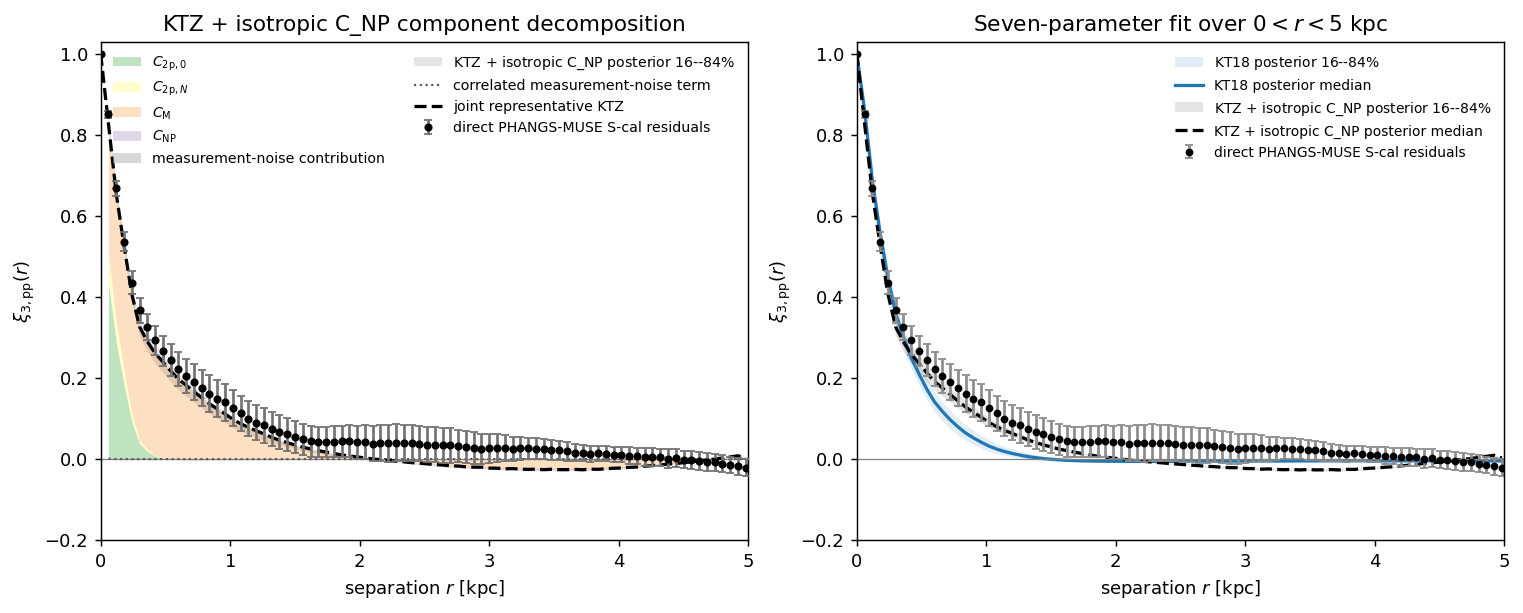

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.6), constrained_layout=True)

# Stack the components from one joint posterior draw selected to be closest
# to the pointwise median complete curve.  This preserves exact additivity.
component_cumulative = np.zeros_like(separation_centres, dtype=float)
for name in component_order:
    next_cumulative = component_cumulative + representative_components[name]
    axes[0].fill_between(
        separation_centres, component_cumulative, next_cumulative,
        color=component_colors[name], alpha=0.50, linewidth=0,
        label=component_labels[name], zorder=1,
    )
    component_cumulative = next_cumulative
noise_cumulative = component_cumulative + observation_noise_bias
axes[0].fill_between(
    separation_centres, component_cumulative, noise_cumulative,
    color="0.72", alpha=0.55, linewidth=0,
    label="measurement-noise contribution", zorder=1,
)
axes[0].fill_between(
    separation_with_zero, xi_ktz_interval_with_zero[0],
    xi_ktz_interval_with_zero[2], color="black", alpha=0.10,
    linewidth=0, label=r"KTZ + isotropic C_NP posterior $16$--$84\%$",
    zorder=2,
)
axes[0].plot(
    separation_centres, observation_noise_bias, color="0.35", ls=":",
    lw=1.2, label="correlated measurement-noise term", zorder=3,
)
axes[0].plot(
    separation_with_zero,
    prepend_zero_anchor(xi_full_ktz_representative, 1.0),
    "k--", lw=1.8, label="joint representative KTZ", zorder=4,
)
axes[0].errorbar(
    separation_with_zero, xi_observed_with_zero, yerr=xi_error_with_zero,
    fmt="o", ms=3.5, color="black", ecolor="0.45", capsize=2,
    label="direct PHANGS-MUSE S-cal residuals", zorder=5,
)
axes[0].axhline(0.0, color="0.5", lw=0.7)
axes[0].set_xlim(0.0, 5.0)
axes[0].set_ylim(-0.20, 1.03)
axes[0].set_xlabel("separation $r$ [kpc]")
axes[0].set_ylabel(r"$\xi_{3,{\rm pp}}(r)$")
axes[0].set_title("KTZ + isotropic C_NP component decomposition")
axes[0].legend(frameon=False, fontsize=7.8, ncol=2)

axes[1].fill_between(
    separation_with_zero, xi_kt18_interval_with_zero[0],
    xi_kt18_interval_with_zero[2], color="#1f77b4", alpha=0.13,
    linewidth=0, label=r"KT18 posterior $16$--$84\%$",
)
axes[1].plot(
    separation_with_zero, xi_kt18_median_with_zero, color="#1f77b4",
    lw=1.8, label="KT18 posterior median",
)
axes[1].fill_between(
    separation_with_zero, xi_ktz_interval_with_zero[0],
    xi_ktz_interval_with_zero[2], color="black", alpha=0.10,
    linewidth=0, label=r"KTZ + isotropic C_NP posterior $16$--$84\%$",
)
axes[1].plot(
    separation_with_zero, xi_ktz_median_with_zero, color="black", lw=1.8,
    ls="--", label="KTZ + isotropic C_NP posterior median",
)
axes[1].errorbar(
    separation_with_zero, xi_observed_with_zero, yerr=xi_error_with_zero,
    fmt="o", ms=3.3, color="black", ecolor="0.55", capsize=2,
    label="direct PHANGS-MUSE S-cal residuals",
)
axes[1].axhline(0.0, color="0.5", lw=0.7)
axes[1].set_xlim(0.0, 5.0)
axes[1].set_ylim(-0.20, 1.03)
axes[1].set_xlabel("separation $r$ [kpc]")
axes[1].set_ylabel(r"$\xi_{3,{\rm pp}}(r)$")
axes[1].set_title(r"Seven-parameter fit over $0<r<5$ kpc")
axes[1].legend(frameon=False, fontsize=7.7)

for filename in (
    "ngc1566_phangs_ktz_vs_kt18.png",
    "ngc1566_phangs_ktz_components.png",
):
    fig.savefig(OUTPUT_DIR / filename, bbox_inches="tight")
display_figure(fig)


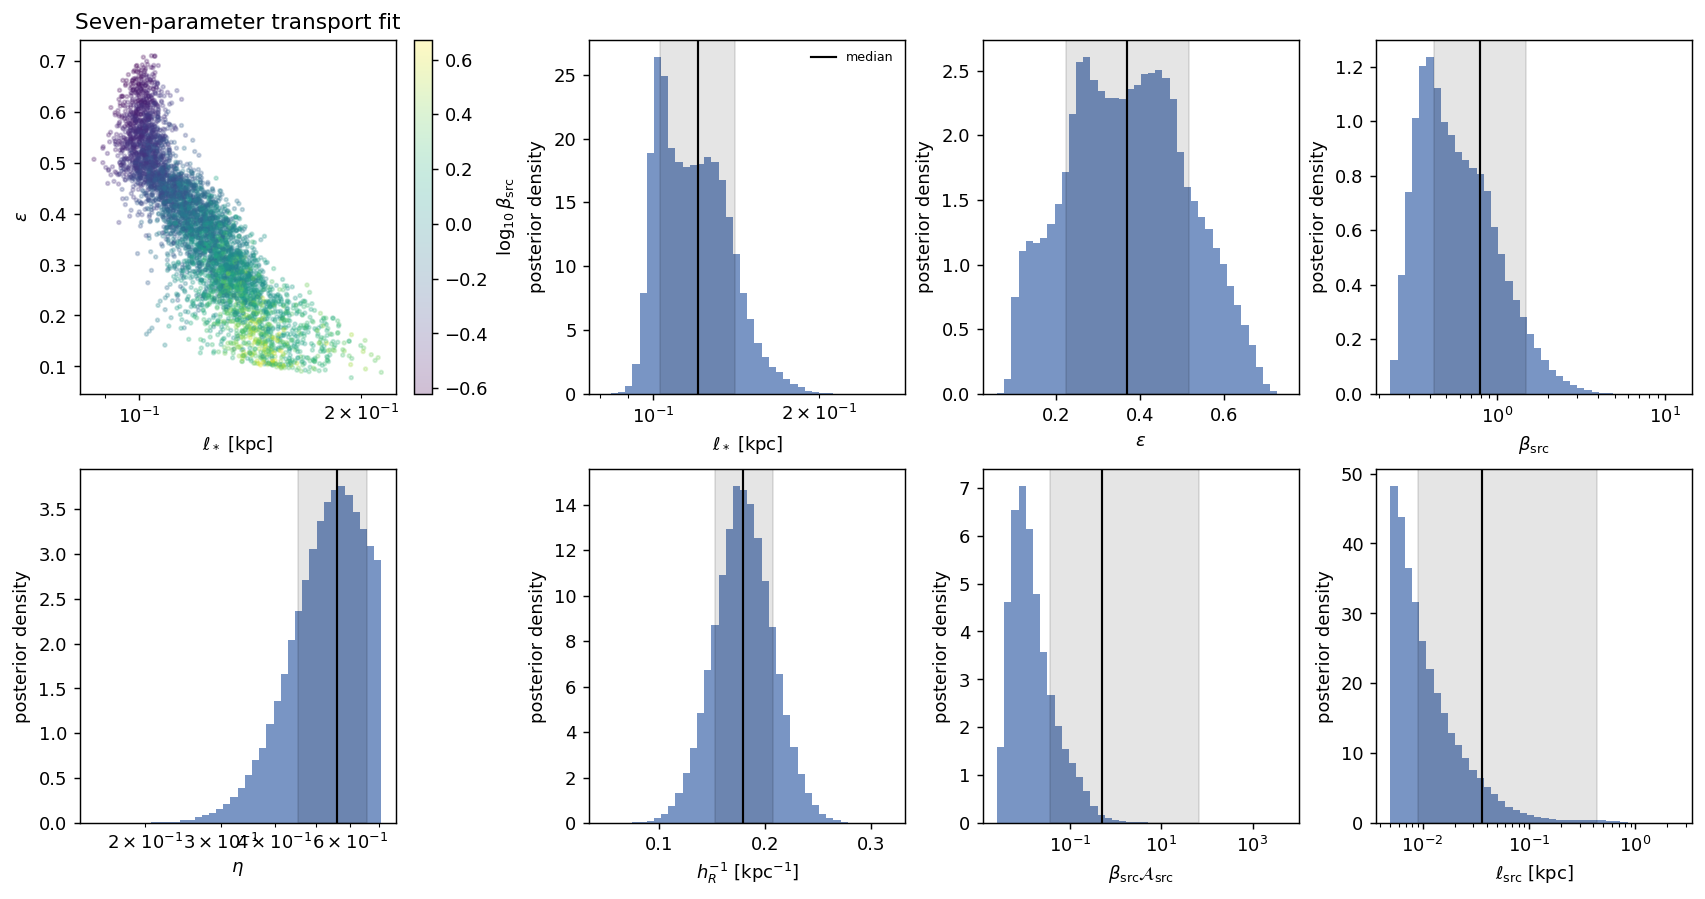

Maximum |posterior-median KTZ + isotropic C_NP - posterior-median KT18|: 0.064


In [14]:
fig, axes = plt.subplots(2, 4, figsize=(13.0, 6.8), constrained_layout=True)
diagnostic_draw = mcmc_rng.choice(
    len(posterior_log_samples), min(5000, len(posterior_log_samples)),
    replace=False,
)
scatter = axes[0, 0].scatter(
    posterior_samples["ell_star"][diagnostic_draw],
    posterior_samples["epsilon"][diagnostic_draw],
    c=np.log10(posterior_samples["beta"][diagnostic_draw]),
    s=4, alpha=0.25, cmap="viridis",
)
axes[0, 0].set_xscale("log")
axes[0, 0].set_xlabel(r"$\ell_*$ [kpc]")
axes[0, 0].set_ylabel(r"$\epsilon$")
axes[0, 0].set_title("Seven-parameter transport fit")
fig.colorbar(scatter, ax=axes[0, 0], label=r"$\log_{10}\beta_{\rm src}$")

diagnostic_specs = (
    (axes[0, 1], "ell_star", r"$\ell_*$ [kpc]", True),
    (axes[0, 2], "epsilon", r"$\epsilon$", False),
    (axes[0, 3], "beta", r"$\beta_{\rm src}$", True),
    (axes[1, 0], "eta", r"$\eta$", True),
    (axes[1, 1], "inv_h_R", r"$h_R^{-1}$ [kpc$^{-1}$]", False),
    (
        axes[1, 2], "beta_A_src",
        r"$\beta_{\rm src}{\cal A}_{\rm src}$", True,
    ),
    (
        axes[1, 3], "source_clustering_length",
        r"$\ell_{\rm src}$ [kpc]", True,
    ),
)
for axis, name, label, use_log_scale in diagnostic_specs:
    interval = credible_interval(posterior_samples[name])
    values = posterior_samples[name]
    histogram_bins = (
        np.geomspace(np.min(values[values > 0]), np.max(values), 41)
        if use_log_scale else 40
    )
    axis.hist(
        values, bins=histogram_bins, density=True,
        color="#4c72b0", alpha=0.75,
    )
    axis.axvline(interval[1], color="black", lw=1.2, label="median")
    axis.axvspan(interval[0], interval[2], color="black", alpha=0.10)
    axis.set_xlabel(label)
    axis.set_ylabel("posterior density")
    if use_log_scale:
        axis.set_xscale("log")
axes[0, 1].legend(frameon=False, fontsize=7.0)
fig.savefig(
    OUTPUT_DIR / "ngc1566_phangs_transport_posterior.png",
    bbox_inches="tight",
)
display_figure(fig)

print(
    "Maximum |posterior-median KTZ + isotropic C_NP - posterior-median KT18|: "
    f"{np.nanmax(np.abs(xi_full_ktz - xi_kt18)):.3f}"
)


## 6. Multi-element extension

This notebook tests the source geometry only in the single-element
correlation.  A multi-element calculation would additionally have to evolve
the H-alpha-derived source harmonics through the element-dependent delay
channels, which is outside the scope of this systematic check.


In [15]:
# Deliberately empty; see the methodological note above.


In [16]:
# Deliberately empty; see the methodological note above.


## 7. Interpretation and limits

- The metallicity statistic now follows the Li21 spaxel-selection logic:
  every diagnostic line has $S/N\geq2$, the [N II] BPT position lies below
  the Kewley boundary, and $\mathrm{EW}({\rm H}\alpha)>6$ Angstrom.  The
  PHANGS nebular mask does not select abundance pixels.
- PHANGS MAPS does not contain a continuum extension.  The EW map therefore
  uses the PSF-matched synthetic SDSS-$r$ flux density and is tied to the
  catalogue's fitted region-integrated H-alpha EWs.  Its per-galaxy calibration
  interval is recorded in the morphology summary and should be propagated as
  a selection sensitivity test.
- The systematic KTZ fit has seven free parameters:
  $\ell_*$, $\epsilon$, $\beta_{\rm src}$, $\eta$, $h_R^{-1}$,
  $\beta_{\rm src}{\cal A}_{\rm src}$, and $\ell_{\rm src}$.  The direct
  H-alpha source grid supplies informative priors on $\eta$ and $h_R^{-1}$.
- The finite-window KTZ quadrature visits every valid unordered pixel pair exactly once; it does not sample pairs.  To keep the 60 pc Li21 grid tractable, exact counts and source-template moments are accumulated in 12 separation subbins per reported bin and 256 midpoint-radius bins.  The cached compression is checked bin by bin against the exact FFT pair counts.
- The likelihood uses all available positive-separation bins from the 60 pc
  grid out to 5 kpc.  The displayed $r=0$ observation and model are fixed to
  unity and do not enter the likelihood.
- Fluxes are matched to a 120 pc Gaussian PSF before ratios are formed.  The
  output is Nyquist-sampled at 60 pc, but independent information remains
  limited by the 120 pc beam.
- Missing or failed-selection cells remain `NaN`.  The FFT numerator is divided
  by an independently transformed binary mask, so internal zero filling never
  treats a missing pixel as zero metallicity fluctuation.
- A separate arithmetic mean is removed in every 0.2 kpc annulus, following
  Li21.  This guards against nonlinear radial calibration structure but also
  removes genuine axisymmetric radial modes.
  Its deterministic covariance projector is applied to both KTZ and KT18
  on the exact valid-pixel mask before the noise transfer.
- The fixed observation transfer combines Li21 Gaussian-beam broadening with
  a 200-realisation line-flux Monte Carlo estimate of correlated noise.  The
  1.12 error inflation and Gaussian noise correlation remain approximations to
  covariance not supplied in the public MAPS product.
- Within KTZ + isotropic C_NP, $C_{\rm NP}$ is the appendix prediction for a Gaussian
  pre-mixing source-pair excess filtered by injection and diffusion; it is not
  a freely added post-mixing Gaussian correlation.
- Repeating the analysis for EW thresholds of 3, 6, and 10 Angstrom, line-S/N
  thresholds of 2, 3, and 5, and alternative target beams is required before
  publication.
- The multi-element panel remains a galaxy-conditioned forecast: MUSE does not
  provide independent abundance maps for all plotted elements, and a frozen
  spiral is a major systematic for delayed channels.


In [17]:
display(Markdown(
    "### Reproducible outputs\n\n"
    + "\n".join(
        f"- `{path.relative_to(ROOT)}`"
        for path in sorted(OUTPUT_DIR.glob("ngc1566_*"))
    )
))

### Reproducible outputs

- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_annular_detrending_transfer.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_annulus_sensitivity.csv`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_covariance_sensitivity.csv`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_kt18_transport_chain.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_kt18_transport_posterior.csv`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_ktz_fit_summary.csv`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_morphology_summary.json`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_muse_scal_7p_ktz_cnp_full_pair_emulator.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_muse_scal_7p_ktz_full_pair_emulator.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_muse_scal_exhaustive_pair_geometry.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_muse_scal_metallicity_residual_pixel_map.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_phangs_ktz_components.png`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_phangs_ktz_vs_kt18.png`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_phangs_morphology.png`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_phangs_radial_selection.png`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_phangs_transport_posterior.png`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_residual_covariance_diagnostics.csv`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_transport_chain.npz`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_transport_posterior.csv`
- `outputs/implications/NGC1566_logspiral_systematic/ngc1566_xi_observed_and_models.csv`